# Challenge 2 — Customer Engagement Score

**Input:** `data_clean.parquet` (one row per customer, built by `1. Data processing.py`).

**Question:** how engaged is each customer, which factors drive or reduce engagement, and is
engagement associated with business outcomes?

**Method in brief.**
* Engagement is measured only from *customer-side* touchpoints: applications and scoring through
  any channel, answered calls, and accepted or self-initiated leads.
* Calls placed by the company are company effort: a control, never engagement.
* Six RFM+ dimensions — Recency, Frequency, Monetary, Interaction, Lead activity, Product
  interaction — are rank-coded 1–5 and combined with objective D-CRITIC weights that never see an
  outcome.
* Segments follow the standard R × FM map.
* Validation is **out of time**: the score uses data up to 4 Jun 2025, and the outcomes are customer
  responses to calls made afterwards. It controls for how often each customer was called.

Run the cells top to bottom. Every number in the text is printed by code; the markdown stays qualitative.

In [1]:
import ast
import hashlib
import json
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd

try:
    IN_NOTEBOOK = get_ipython().__class__.__name__ == 'ZMQInteractiveShell'  # noqa: F821
except NameError:
    IN_NOTEBOOK = False
if not IN_NOTEBOOK:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy.stats import rankdata, spearmanr

if IN_NOTEBOOK:
    from IPython.display import display

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
SOURCE = ROOT.parent / 'data_clean.parquet'
TABLES, OUTPUTS, REPORTS = ROOT / 'tables', ROOT / 'outputs', ROOT / 'reports'
FIGURES = ROOT / 'figures' / 'challenge2'
for folder in (TABLES, OUTPUTS, REPORTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# Time frame. Contracts, leads and behaviour end on 4 Jun 2025; the parquet's *_ASOF and *_90D
# columns use this exclusive cutoff (see `1. Data processing.py`). Calls continue to 31 Aug 2026.
CUTOFF = pd.Timestamp('2025-06-05')
REFERENCE_DATE = pd.Timestamp('2025-06-04')
WINDOW_START = CUTOFF - pd.Timedelta(days=90)      # 7 Mar 2025, the window behind every *_90D column
CALL_DATA_START = pd.Timestamp('2025-01-01')       # first call in CALL.csv
SELF_LEAD_SOURCES = {'GMA', 'LANDING PAGE', 'SOB'} # customer-originated lead sources (StructureTable, LEADS)
DIMENSIONS = ['R', 'F', 'M', 'I', 'L', 'P']
BOOTSTRAP_REPLICATES, SEED = 200, 20251018

# The palette and chart style have one source: `2. EDA scores.py`. Only its colour constants and
# its `plt.rcParams.update(...)` call are read and executed here; the rest of that script never runs.
PALETTE_SOURCE = ROOT / '2. EDA scores.py'
PALETTE_NAMES = ('NAVY', 'BLUE', 'TEAL', 'AMBER', 'CORAL', 'SLATE', 'BG')

def load_palette(path):
    tree = ast.parse(path.read_text(encoding='utf-8'))
    keep = [node for node in tree.body
            if (isinstance(node, ast.Assign) and any(isinstance(target, ast.Tuple) and
                {e.id for e in target.elts if isinstance(e, ast.Name)} <= set(PALETTE_NAMES) for target in node.targets))
            or (isinstance(node, ast.Expr) and ast.unparse(node).startswith('plt.rcParams.update('))]
    namespace = {'plt': plt}
    exec(compile(ast.Module(body=keep, type_ignores=[]), str(path), 'exec'), namespace)
    missing = [name for name in PALETTE_NAMES if name not in namespace]
    if missing:
        raise ValueError(f'{path.name} no longer defines {missing}')
    return [namespace[name] for name in PALETTE_NAMES]

NAVY, BLUE, TEAL, AMBER, CORAL, SLATE, BG = load_palette(PALETTE_SOURCE)

def tint(color, alpha=.5):
    """Lighter shade of a palette colour (same hue, partial opacity) for secondary marks."""
    return to_rgba(color, alpha)

## 1. Load and check the customer file
The hard checks enforce the grain, the cutoff, and the consistency between the as-of and total
columns. Soft findings go into the data-quality table.

In [2]:
with SOURCE.open('rb') as handle:
    source_hash = hashlib.file_digest(handle, 'sha256').hexdigest()

COLUMNS = {
    'SKP_CLIENT': 'client', 'AVG_SESSION_PER_WEEK_2025': 'app_sessions_week',
    'CONTRACT_PRODUCT_COUNT': 'products_applied', 'CONTRACT_SIGNED_CREDIT_TOTAL': 'signed_credit_total',
    'CONTRACT_REJECTED_COUNT': 'rejected_cases', 'LAST_CONTRACT_APPLICATION_AT': 'last_application_at',
    'LAST_CONTRACT_SIGNED_AT': 'last_signed_at', 'LATEST_CONTRACT_STATUS': 'latest_status',
    'CALL_COUNT': 'calls_all', 'CALL_SYSTEM_ANSWER_COUNT': 'answered_all',
    'CALL_INBOUND_COUNT': 'inbound_all', 'CALL_DISPOSITION_REFUSE_COUNT': 'refused_all',
    'CALL_COUNT_ASOF_2025_06_04': 'calls', 'CALL_COUNT_90D_ASOF_2025_06_04': 'calls_90d',
    'CALL_SYSTEM_ANSWER_ASOF_2025_06_04': 'answered', 'CALL_REFUSE_ASOF_2025_06_04': 'refused',
    'CALL_INBOUND_ASOF_2025_06_04': 'inbound', 'LAST_CALL_ASOF_2025_06_04': 'last_call_at',
    'LAST_CALL_RESULT_ASOF_2025_06_04': 'last_call_result',
    'LEAD_COUNT': 'leads', 'LEAD_DEAL_COUNT': 'lead_deals', 'LEAD_NOT_INTERESTED_COUNT': 'lead_not_interested',
    'LEAD_COUNT_90D_ASOF_2025_06_04': 'leads_90d', 'LEAD_DEAL_90D_ASOF_2025_06_04': 'lead_deals_90d',
    'LAST_LEAD_AT': 'last_lead_at', 'LAST_LEAD_SOURCE': 'last_lead_source',
    'LAST_LEAD_REASON': 'last_lead_reason', 'LEAD_ACCEPTED_SENTINEL_COUNT': 'lead_sob_sentinel',
    'BEHAVIOR_EVENT_COUNT': 'behavior_events', 'BEHAVIOR_EVENTS_90D_ASOF_2025_06_04': 'behavior_events_90d',
    'BEHAVIOR_PRODUCTS_90D_ASOF_2025_06_04': 'behavior_products_90d', 'LAST_BEHAVIOR_AT': 'last_behavior_at',
    'LAST_BEHAVIOR_ACTION': 'last_behavior_action', 'LAST_BEHAVIOR_ACTION_AMBIGUOUS': 'last_action_ambiguous',
}
d = pd.read_parquet(SOURCE, columns=list(COLUMNS)).rename(columns=COLUMNS)
n = len(d)
checks = []

def check(name, value, passed=True, hard=False):
    checks.append({'check': name, 'value': value, 'passed': bool(passed), 'hard_rule': hard})
    if hard and not passed:
        raise ValueError(f'Data check failed: {name} ({value})')

check('one row per customer', f'{n:,} rows / {d.client.nunique():,} ids', d.client.is_unique and n > 0, hard=True)
for small, large in [('calls', 'calls_all'), ('answered', 'answered_all'), ('inbound', 'inbound_all'),
                     ('refused', 'refused_all'), ('calls_90d', 'calls'), ('leads_90d', 'leads'),
                     ('lead_deals_90d', 'lead_deals'), ('lead_deals', 'leads'),
                     ('behavior_events_90d', 'behavior_events')]:
    bad = int((d[small] > d[large]).sum())
    check(f'{small} <= {large}', bad, bad == 0, hard=True)
for column in ('last_call_at', 'last_lead_at', 'last_behavior_at', 'last_application_at', 'last_signed_at'):
    latest = d[column].max()
    check(f'{column} before cutoff', str(latest), latest < CUTOFF, hard=True)
check('refusals coded without a system ANSWER (customers)', int((d.refused > d.answered).sum()))
check('customers with calls after the cutoff', int((d.calls_all > d.calls).sum()))
check('ambiguous latest behaviour action (customers)', int(d.last_action_ambiguous.sum()))
check('leads with SOB acceptance sentinel 3000-01-01', int(d.lead_sob_sentinel.sum()))
check('customers with any app session in 2025', int((d.app_sessions_week > 0).sum()))
print(f'{n:,} customers loaded; {len(checks)} checks run; source SHA-256 {source_hash[:16]}…')

1,000,528 customers loaded; 20 checks run; source SHA-256 6c48fc813a5927cf…


## 2. Touchpoint taxonomy
Engagement must reflect what the **customer** does.

| Class | Columns used | Role |
|---|---|---|
| Customer-side: application / scoring | `BEHAVIOR_*` (APP, WEB, SA, TLS, partner, SOB) | Engagement |
| Customer-side: answered calls | answered minus refused calls, as of cutoff | Engagement (Interaction) |
| Customer-side: leads | accepted offers (`Deal`); latest lead from GMA / landing page / SOB | Engagement (Lead) |
| Company effort | calls placed by the company | Control and baseline only |
| Lead records | every lead row | Not engagement on its own (see section 8) |
| Collection calls | not separable in the customer file | Limitation |

In [3]:
d['net_answered'] = (d.answered - d.refused).clip(lower=0)
d['self_lead_last'] = d.last_lead_source.isin(SELF_LEAD_SOURCES) | d.last_lead_reason.eq('Deal')
side = {
    'Application / scoring event': d.behavior_events > 0,
    'Answered call (net of refusals)': d.net_answered > 0,
    'Accepted or self-initiated lead': (d.lead_deals > 0) | d.self_lead_last,
    'Inbound call': d.inbound > 0,
    'Called by the company': d.calls > 0,
    'Any lead record': d.leads > 0,
}
taxonomy = pd.DataFrame({'touchpoint': list(side),
    'class': ['customer-side'] * 4 + ['company effort', 'lead record'],
    'customers': [int(mask.sum()) for mask in side.values()]})
taxonomy['share'] = taxonomy.customers / n
taxonomy.to_csv(TABLES / 'c2_touchpoint_taxonomy.csv', index=False)

### Chart helpers
Charts carry **no titles**. Each one is followed by a markdown caption with its figure number
and source. The helper refuses to save a figure that has a title.

In [4]:
FIGURE_LOG, INSIGHTS = [], {}
FOOTER = f'Source: data_clean.parquet | customer-level, as of 4 Jun 2025 | n = {n:,}'
FORWARD_FOOTER = 'Source: data_clean.parquet | score as of 4 Jun 2025; calls 5 Jun 2025 – 31 Aug 2026'

def new_figure(nrows=1, ncols=1, footer=FOOTER, **kwargs):
    fig, axes = plt.subplots(nrows, ncols, figsize=(12.8, 7.2), layout='constrained', **kwargs)
    fig.get_layout_engine().set(rect=(0, .045, 1, .955))
    fig.text(.01, .012, footer, fontsize=10, color=SLATE, ha='left', va='bottom')
    return fig, axes

def finish(fig, filename):
    if fig._suptitle is not None or any(ax.get_title(loc) for ax in fig.axes for loc in ('left', 'center', 'right')):
        raise ValueError(f'{filename}: charts must not have titles')
    fig.savefig(FIGURES / filename, dpi=180, facecolor=BG)
    FIGURE_LOG.append(filename)
    if IN_NOTEBOOK:
        display(fig)
    plt.close(fig)

def say(key, text):
    INSIGHTS[key] = text
    print('Insight:', text)

def count_axis(ax, axis='x'):
    formatter = FuncFormatter(lambda value, _: f'{value / 1e6:.1f}M' if abs(value) >= 1e6
        else f'{value / 1e3:.0f}k' if abs(value) >= 1e3 else f'{value:.0f}')
    (ax.xaxis if axis == 'x' else ax.yaxis).set_major_formatter(formatter)

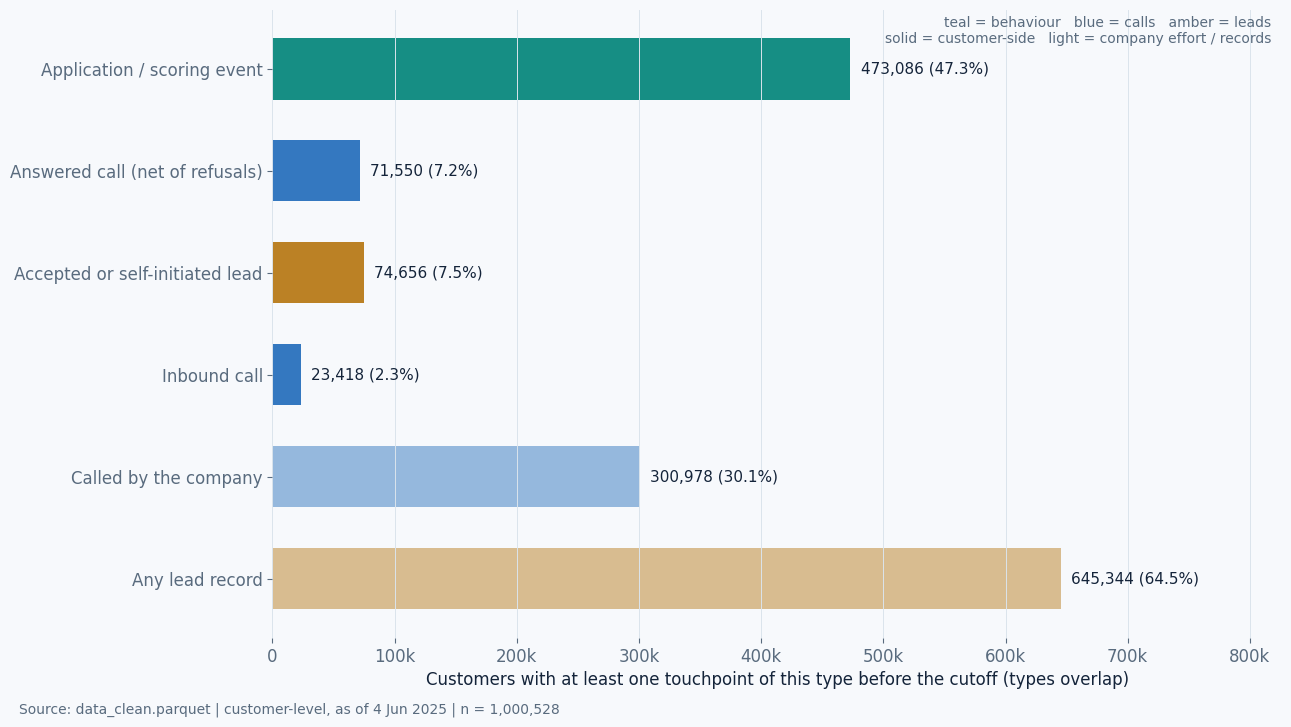

Insight: 300,978 customers were called before the cutoff, but only 71,550 answered at least one call net of refusals and 23,418 ever called in.


In [5]:
fig, ax = new_figure()
colors = [TEAL, BLUE, AMBER, BLUE, tint(BLUE), tint(AMBER)]
positions = np.arange(len(taxonomy))
ax.barh(positions, taxonomy.customers, color=colors, height=.6)
ax.set_yticks(positions, taxonomy.touchpoint)
ax.invert_yaxis()
ax.grid(axis='x')
limit = taxonomy.customers.max() * 1.28
ax.set_xlim(0, limit)
ax.set_xlabel('Customers with at least one touchpoint of this type before the cutoff (types overlap)')
count_axis(ax)
for i, row in taxonomy.iterrows():
    ax.text(row.customers + limit * .01, i, f'{row.customers:,} ({row.share:.1%})', va='center', fontsize=11)
ax.text(.99, .99, 'teal = behaviour   blue = calls   amber = leads\nsolid = customer-side   light = company effort / records',
        transform=ax.transAxes, ha='right', va='top', color=SLATE, fontsize=10)
finish(fig, '01_touchpoint_taxonomy.png')
say('taxonomy', f"{taxonomy.customers[4]:,} customers were called before the cutoff, but only "
    f"{taxonomy.customers[1]:,} answered at least one call net of refusals and {taxonomy.customers[3]:,} ever called in.")

**Figure 1 — Customer-side touchpoints versus company effort.** The number of customers with at
least one touchpoint of each type before the cutoff; one customer can appear in several bars.
*Source:* `data_clean.parquet` (behaviour, call and lead aggregates as of 4 Jun 2025).

## 3. RFM+ dimensions
RFM (Recency, Frequency, Monetary) is the backbone. Recent financial-services studies use dated
RFM measures as core behavioural inputs (Mena et al., 2024; Brito et al., 2024). Following the
RFMA extension for banking (Mosa et al., 2023), the three further dimensions the brief requires
are added: Interaction, Lead activity and Product interaction.

| Dim | Raw measure | Window |
|---|---|---|
| R | days since the last customer-side touchpoint (behaviour event, answered call, accepted or self-initiated lead) | up to the cutoff |
| F | application / scoring events | last 90 days |
| M | total credit amount of signed contracts (monetary value of the relationship) | lifetime |
| I | answered calls minus refusals | call log up to the cutoff |
| L | lead offers accepted (`Deal`) | lifetime |
| P | distinct products applied for | lifetime |

**Recency dates.** The customer file stores only the *latest* call and lead. Two cases need a bound:
* The latest call was not answered but an earlier one was. The answer date is then only known to
  lie after the start of the call log, so the conservative bound (the start of the call log) is used.
* A recent `Deal` is not the latest lead. Its date is bounded by the start of the 90-day window.

Customers whose only customer-side evidence has no recoverable date get the least-recent R score.

In [6]:
last_answered = d.last_call_at.where(d.last_call_result.eq('ANSWER'))
answered_censored = last_answered.isna() & (d.answered > 0)
last_answered = last_answered.mask(answered_censored, CALL_DATA_START)
last_customer_lead = d.last_lead_at.where(d.self_lead_last)
deal_censored = last_customer_lead.isna() & (d.lead_deals_90d > 0)
last_customer_lead = last_customer_lead.mask(deal_censored, WINDOW_START)
touch_dates = pd.DataFrame({'behaviour': d.last_behavior_at, 'call': last_answered, 'lead': last_customer_lead})
stamp = touch_dates.apply(lambda column: column.values.astype('datetime64[ns]').astype('int64'))
stamp = stamp.where(touch_dates.notna(), np.iinfo('int64').min)
d['last_touch_at'] = touch_dates.max(axis=1)
d['touch_source'] = np.where(d.last_touch_at.isna(), None, np.array(touch_dates.columns)[stamp.to_numpy().argmax(axis=1)])
d['days_since_touch'] = (REFERENCE_DATE - d.last_touch_at.dt.normalize()).dt.days
d['customer_touch'] = d.last_touch_at.notna() | (d.lead_deals > 0) | (d.net_answered > 0) | (d.behavior_events > 0)
check('answered-call dates bounded by call-log start', int(answered_censored.sum()))
check('recent Deal dates bounded by window start', int(deal_censored.sum()))
check('customer-side evidence without recoverable date', int((d.customer_touch & d.last_touch_at.isna()).sum()))

CHANNEL = {'APP SCORING': 'mobile app', 'WEB SCORING': 'website', 'SA SCORING': 'sales agent',
           'TLS SCORING': 'telesales', 'Partner Site SCORING': 'partner site'}
behaviour_channel = d.last_behavior_action.map(CHANNEL)
behaviour_channel = behaviour_channel.mask(d.last_behavior_action.fillna('').str.startswith('SOB'), 'sales-on-board QR/link')
behaviour_channel = behaviour_channel.fillna('several channels at once')
d['touch_channel'] = np.select(
    [d.touch_source.eq('behaviour'), d.touch_source.eq('call'), d.touch_source.eq('lead') & d.last_lead_reason.eq('Deal'),
     d.touch_source.eq('lead')],
    [behaviour_channel, 'an answered call', 'an accepted lead offer', 'a self-initiated lead'], default='')
d['digital_last_action'] = d.last_behavior_action.isin(['APP SCORING', 'WEB SCORING']) | \
    d.last_behavior_action.fillna('').str.startswith('SOB')

raw = pd.DataFrame({'R': d.days_since_touch.astype(float), 'F': d.behavior_events_90d.astype(float),
    'M': d.signed_credit_total.fillna(0).astype(float), 'I': d.net_answered.astype(float),
    'L': d.lead_deals.astype(float), 'P': d.products_applied.astype(float)})
print(raw.describe(percentiles=[.5, .9, .99]).T.round(1).to_string())

       count        mean         std  min         50%         90%          99%          max
R   508544.0       168.2       187.5  0.0       136.0       420.0        857.0       2064.0
F  1000528.0         0.8         3.1  0.0         0.0         3.0         12.0        340.0
M  1000528.0  30800963.7  49956304.3  0.0  13995000.0  78000000.0  252706650.0  790653000.0
I  1000528.0         0.1         0.5  0.0         0.0         0.0          2.0         22.0
L  1000528.0         0.1         0.3  0.0         0.0         0.0          1.0          9.0
P  1000528.0         1.6         0.8  0.0         1.0         3.0          4.0          6.0


## 4. Rank coding to 1–5
Each dimension is coded by rank, as in classic RFM quintile coding (Hughes, 1994, origin).
* **R:** quintiles among customers with a dated touchpoint; the most recent fifth scores 5.
* **Counts and amounts (F, M, I, L, P):** zero means *no activity* and scores 1; positive values are
  split into quartiles scored 2–5.
* **Ties** share one score: percentiles use mid-ranks, so a heavy tie lands at its average position.

Cut points are recomputed from the data on every run and saved with their observed ranges.

In [7]:
def rank_bins(values, k):
    percentile = rankdata(values, method='average') / len(values)
    return np.clip(np.ceil(percentile * k), 1, k).astype(int)

def recency_score(days):
    days = np.asarray(days, float)
    score = np.ones(len(days), int)
    dated = np.isfinite(days)
    score[dated] = rank_bins(-days[dated], 5)
    return score

def activity_score(values):
    values = np.asarray(values, float)
    score = np.ones(len(values), int)
    positive = values > 0
    score[positive] = 1 + rank_bins(values[positive], 4)
    return score

S = pd.DataFrame({'R': recency_score(raw.R)} | {dim: activity_score(raw[dim]) for dim in DIMENSIONS[1:]})
cut_rows = []
for dim in DIMENSIONS:
    for level in range(1, 6):
        member = raw[dim][S[dim] == level]
        cut_rows.append({'dimension': dim, 'score': level, 'customers': len(member),
                         'raw_min': member.min() if len(member) else None,
                         'raw_max': member.max() if len(member) else None,
                         'undated_or_zero': int(member.isna().sum() if dim == 'R' else (member == 0).sum())})
cuts = pd.DataFrame(cut_rows)
cuts.to_csv(TABLES / 'c2_score_cut_points.csv', index=False)
print(cuts.pivot(index='score', columns='dimension', values='customers')[DIMENSIONS].to_string())

dimension       R       F       M       I       L       P
score                                                    
1          593158  842262  203163  928978  948779    4079
2          102984   52198  199340       0       0       0
3          100862   47065  199350   54184   46819  539796
4          101065   23552  199315       0       0  298237
5          102459   35451  199360   17366    4930  158416


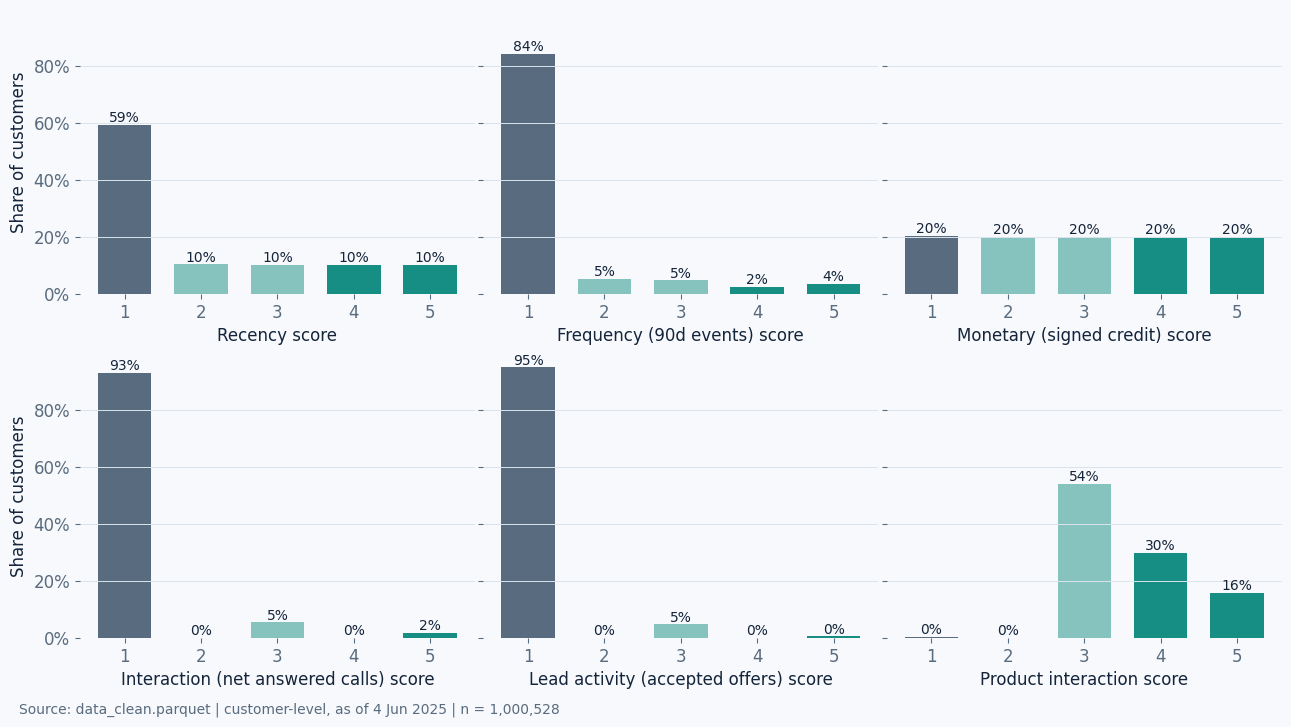

Insight: Share of customers at the floor score (no activity, or least recent for R): R 59%, F 84%, M 20%, I 93%, L 95%, P 0%.


In [8]:
labels = {'R': 'Recency', 'F': 'Frequency (90d events)', 'M': 'Monetary (signed credit)',
          'I': 'Interaction (net answered calls)', 'L': 'Lead activity (accepted offers)', 'P': 'Product interaction'}
fig, axes = new_figure(2, 3, sharey=True)
for ax, dim in zip(axes.flat, DIMENSIONS):
    share = S[dim].value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    ax.bar(share.index, share.values, color=[SLATE, tint(TEAL), tint(TEAL), TEAL, TEAL], width=.7)
    ax.set_xticks(range(1, 6))
    ax.set_xlabel(f'{labels[dim]} score')
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=None))
    ax.grid(axis='y')
    for level, value in share.items():
        ax.text(level, value + .01, f'{value:.0%}', ha='center', fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel('Share of customers')
finish(fig, '02_dimension_scores.png')
floor_share = {dim: float((S[dim] == 1).mean()) for dim in DIMENSIONS}
say('dimensions', 'Share of customers at the floor score (no activity, or least recent for R): ' +
    ', '.join(f'{dim} {share:.0%}' for dim, share in floor_share.items()) + '.')

**Figure 2 — Distribution of the six dimension scores.** A score of 1 means no activity (for R: the
least recent fifth, or no recoverable date). Scores 2–5 split active customers by rank; a value
shared by many customers fills a single score, which is why some scores are empty.
*Source:* `data_clean.parquet`, as of 4 Jun 2025.

## 5. Weights from D-CRITIC
Weights are derived **without looking at any outcome**, so the validation below is not circular.
CRITIC gives more weight to a dimension that varies more and overlaps less with the others.
D-CRITIC (Krishnan et al., 2021) measures that overlap with **distance correlation**, which also
captures non-linear dependence:

`C_j = σ_j · Σ_k (1 − dCor_jk)`, `w_j = C_j / Σ C`, on scores rescaled to 0–1.

Every score takes only five values, so distance correlation is computed **exactly on the full
population** from the 5 × 5 joint frequency table, with no sampling. A brute-force check on a
random sample verifies the formula. Equal weights and classic Pearson-based CRITIC (Diakoulaki et
al., 1995, origin) are kept as sensitivity schemes.

In [9]:
LEVELS = np.arange(1, 6, dtype=float)
DISTANCE = np.abs(LEVELS[:, None] - LEVELS[None, :])

def centred_distance(prob):
    row = DISTANCE @ prob
    return DISTANCE - row[:, None] - row[None, :] + prob @ row

def distance_correlation_discrete(x, y):
    joint = np.zeros((5, 5))
    np.add.at(joint, (x - 1, y - 1), 1.0)
    joint /= joint.sum()
    a, b = centred_distance(joint.sum(1)), centred_distance(joint.sum(0))
    dcov = np.einsum('uw,vz,uv,wz->', joint, joint, a, b)
    var_x = np.einsum('u,v,uv->', joint.sum(1), joint.sum(1), a * a)
    var_y = np.einsum('w,z,wz->', joint.sum(0), joint.sum(0), b * b)
    return float(np.sqrt(max(dcov, 0) / np.sqrt(var_x * var_y))) if var_x > 0 and var_y > 0 else 0.0

def distance_correlation_bruteforce(x, y):
    def centred(v):
        m = np.abs(v[:, None] - v[None, :]).astype(float)
        return m - m.mean(0) - m.mean(1)[:, None] + m.mean()
    a, b = centred(np.asarray(x, float)), centred(np.asarray(y, float))
    return float(np.sqrt((a * b).mean() / np.sqrt((a * a).mean() * (b * b).mean())))

rng = np.random.default_rng(SEED)
sample = rng.choice(n, 1500, replace=False)
gap = max(abs(distance_correlation_discrete(S[x].to_numpy()[sample], S[y].to_numpy()[sample])
              - distance_correlation_bruteforce(S[x].to_numpy()[sample], S[y].to_numpy()[sample]))
          for x, y in [('R', 'F'), ('M', 'P'), ('I', 'L')])
check('exact discrete dCor equals brute force (max abs gap)', f'{gap:.2e}', gap < 1e-9, hard=True)

X = (S[DIMENSIONS].to_numpy(float) - 1) / 4
sigma = X.std(axis=0)
pearson = np.corrcoef(X, rowvar=False)
dcor = np.array([[distance_correlation_discrete(S[a].to_numpy(), S[b].to_numpy()) for b in DIMENSIONS]
                 for a in DIMENSIONS])
critic_info = sigma * (1 - pearson).sum(axis=1)
dcritic_info = sigma * (1 - dcor).sum(axis=1)
WEIGHTS = {'D-CRITIC (primary)': dcritic_info / dcritic_info.sum(),
           'CRITIC (Pearson)': critic_info / critic_info.sum(),
           'Equal weights': np.full(len(DIMENSIONS), 1 / len(DIMENSIONS))}
weights_table = pd.DataFrame(WEIGHTS, index=DIMENSIONS).round(4)
weights_table['sigma'] = sigma.round(4)
weights_table.to_csv(TABLES / 'c2_weights.csv')
pd.DataFrame(dcor, index=DIMENSIONS, columns=DIMENSIONS).round(4).to_csv(TABLES / 'c2_distance_correlation.csv')
print(weights_table.to_string())

   D-CRITIC (primary)  CRITIC (Pearson)  Equal weights   sigma
R              0.2145            0.2166         0.1667  0.3552
F              0.1647            0.1658         0.1667  0.2359
M              0.2473            0.2450         0.1667  0.3542
I              0.1428            0.1431         0.1667  0.1701
L              0.1043            0.1046         0.1667  0.1258
P              0.1265            0.1248         0.1667  0.1904


## 6. Engagement Score
`Engagement = 100 × Σ w_j · (s_j − 1) / 4`: a linear map of the weighted 1–5 scores onto 0–100,
with no further rescaling.

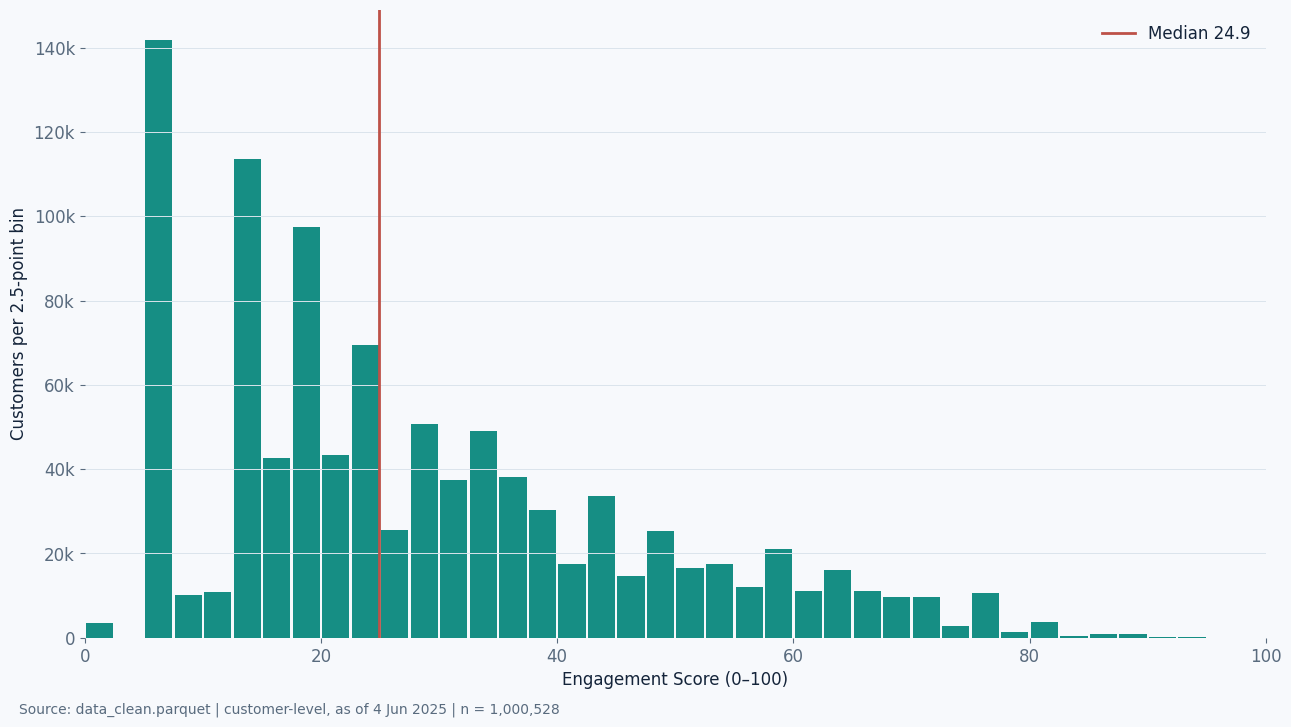

Insight: Median Engagement Score 24.9; 14.6% of customers score 50 or more; 0.3% score exactly 0.


In [10]:
def weighted_score(weights, dims=DIMENSIONS):
    idx = [DIMENSIONS.index(dim) for dim in dims]
    w = np.asarray(weights)[idx]
    return 100 * (X[:, idx] @ (w / w.sum()))

W = WEIGHTS['D-CRITIC (primary)']
d['engagement_score'] = weighted_score(W).round(2)
scheme_scores = {name: weighted_score(w) for name, w in WEIGHTS.items()}
check('engagement score within [0, 100]', f"{d.engagement_score.min()}–{d.engagement_score.max()}",
      d.engagement_score.between(0, 100).all(), hard=True)

fig, ax = new_figure()
ax.hist(d.engagement_score, bins=np.arange(0, 102.5, 2.5), color=TEAL, rwidth=.92)
median = d.engagement_score.median()
ax.axvline(median, color=CORAL, linewidth=2, label=f'Median {median:.1f}')
ax.legend(frameon=False, loc='upper right')
ax.set(xlim=(0, 100), xlabel='Engagement Score (0–100)', ylabel='Customers per 2.5-point bin')
ax.grid(axis='y')
count_axis(ax, 'y')
finish(fig, '03_engagement_score_distribution.png')
say('score', f'Median Engagement Score {median:.1f}; {(d.engagement_score >= 50).mean():.1%} of customers '
    f'score 50 or more; {(d.engagement_score == 0).mean():.1%} score exactly 0.')

**Figure 3 — Distribution of the Engagement Score.** All customers, D-CRITIC weights; the line
marks the median. *Source:* `data_clean.parquet`, as of 4 Jun 2025.

## 7. Segments: the standard R × FM map
Segments use the widely used RFM grid on R and FM, where FM is the mean of F and M rounded half up.
The rules are applied in a fixed precedence order, so segments never overlap.

Segments do **not** depend on the weights. For Challenge 3 they are merged into business tiers.
Customers with no customer-side touchpoint are kept apart:
* *Called, no response* — the company called them;
* *No interaction recorded* — otherwise.

In [11]:
SEGMENT_RULES = [  # (name, rule on R and FM), applied in this precedence order
    ('Champions', lambda r, fm: (r >= 4) & (fm >= 4)), ("Can't Lose Them", lambda r, fm: (r == 1) & (fm >= 4)),
    ('At Risk', lambda r, fm: (r <= 2) & (fm >= 3)), ('Loyal', lambda r, fm: (r == 3) & (fm >= 3)),
    ('New / Recent', lambda r, fm: (r == 5) & (fm == 1)), ('Promising', lambda r, fm: (r == 4) & (fm == 1)),
    ('Potential Loyalist', lambda r, fm: (r >= 4) & (fm <= 3)), ('Need Attention', lambda r, fm: (r == 3) & (fm == 2)),
    ('About to Sleep', lambda r, fm: (r == 3) & (fm == 1)), ('Hibernating', lambda r, fm: (r == 2) & (fm <= 2)),
    ('Lost', lambda r, fm: (r == 1) & (fm <= 2))]

def assign_segments(r, fm):
    return np.select([rule(r, fm) for _, rule in SEGMENT_RULES], [name for name, _ in SEGMENT_RULES], default='UNASSIGNED')

R, F, M = S.R.to_numpy(), S.F.to_numpy(), S.M.to_numpy()
FM = np.floor((F + M) / 2 + .5).astype(int)
segment = assign_segments(R, FM)
check('every customer matched by the segment grid', int((segment == 'UNASSIGNED').sum()),
      (segment != 'UNASSIGNED').all(), hard=True)
TIER_OF = {'Champions': 'Highly engaged', 'Loyal': 'Highly engaged',
           'Potential Loyalist': 'Growing', 'New / Recent': 'Growing', 'Promising': 'Growing',
           'Need Attention': 'Cooling', 'About to Sleep': 'Cooling',
           'At Risk': 'Slipping high-value', "Can't Lose Them": 'Slipping high-value',
           'Hibernating': 'Dormant', 'Lost': 'Dormant'}
TIERS = ['Highly engaged', 'Growing', 'Cooling', 'Slipping high-value', 'Dormant',
         'Called, no response', 'No interaction recorded']
TIER_COLORS = [TEAL, tint(TEAL), AMBER, CORAL, SLATE, BLUE, NAVY]
no_touch = ~d.customer_touch.to_numpy()
d['rfm_segment'] = np.where(no_touch, 'No customer-side touchpoint', segment)
d['engagement_tier'] = np.where(no_touch & (d.calls > 0), 'Called, no response',
                        np.where(no_touch, 'No interaction recorded', pd.Series(segment).map(TIER_OF)))
d['FM_score'] = FM

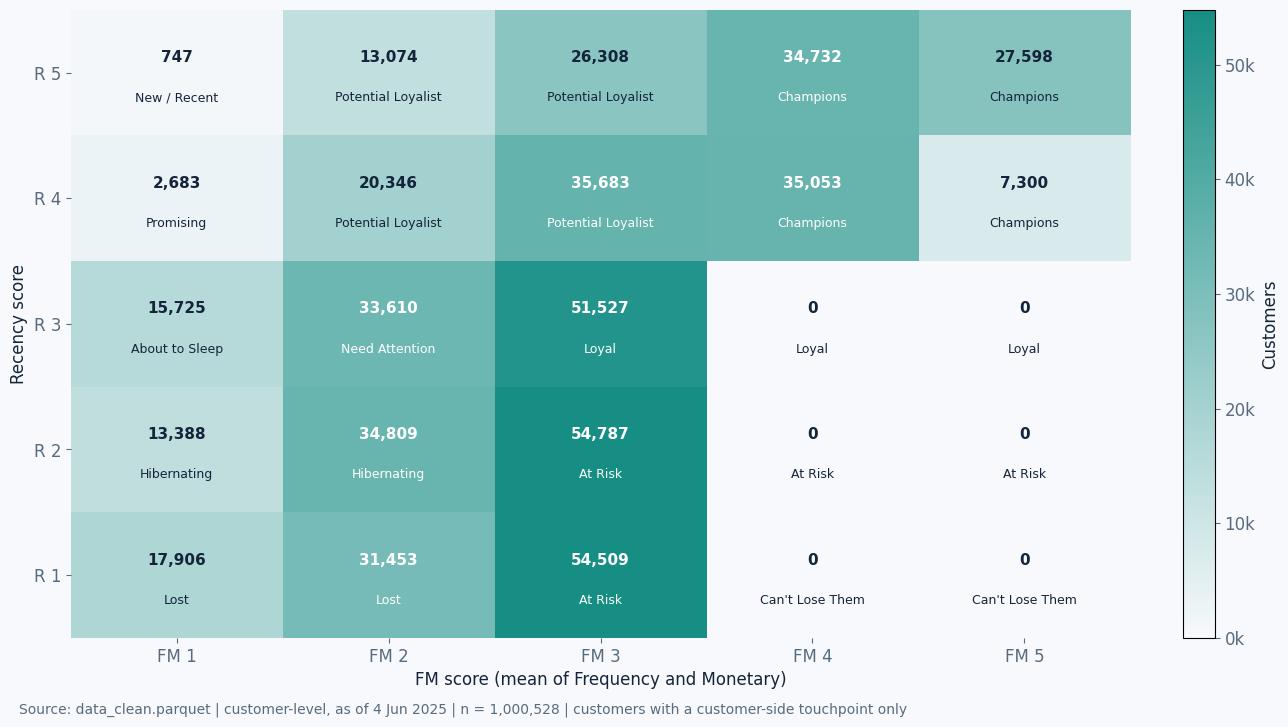

Insight: Largest RFM segments among customers with a customer-side touchpoint: At Risk (109,296), Champions (104,683), Potential Loyalist (95,411).


In [12]:
active = ~no_touch
grid = pd.crosstab(pd.Series(R[active], name='R'), pd.Series(FM[active], name='FM')).reindex(
    index=range(5, 0, -1), columns=range(1, 6), fill_value=0)
cell_segment = {(r, fm): str(assign_segments(np.array([r]), np.array([fm]))[0])
                for r in range(1, 6) for fm in range(1, 6)}
fig, ax = new_figure(footer=FOOTER + ' | customers with a customer-side touchpoint only')
image = ax.imshow(grid.to_numpy(), cmap=LinearSegmentedColormap.from_list('engagement', [BG, TEAL]), aspect='auto')
ax.set_xticks(range(5), [f'FM {v}' for v in range(1, 6)])
ax.set_yticks(range(5), [f'R {v}' for v in range(5, 0, -1)])
ax.set_xlabel('FM score (mean of Frequency and Monetary)')
ax.set_ylabel('Recency score')
peak = grid.to_numpy().max()
for i, r in enumerate(range(5, 0, -1)):
    for j, fm in enumerate(range(1, 6)):
        value = grid.loc[r, fm]
        ink = 'white' if value > peak * .55 else NAVY
        ax.text(j, i - .12, f'{value:,}', ha='center', va='center', color=ink, fontsize=11, fontweight='semibold')
        ax.text(j, i + .2, cell_segment[(r, fm)], ha='center', va='center', color=ink, fontsize=9)
fig.colorbar(image, ax=ax, label='Customers', format=FuncFormatter(lambda v, _: f'{v / 1e3:.0f}k'))
finish(fig, '04_rfm_segment_map.png')
largest = pd.Series(segment[active]).value_counts()
say('segment_map', f'Largest RFM segments among customers with a customer-side touchpoint: {largest.index[0]} '
    f'({largest.iloc[0]:,}), {largest.index[1]} ({largest.iloc[1]:,}), {largest.index[2]} ({largest.iloc[2]:,}).')

**Figure 4 — RFM segment map (Recency × FM).** Customer counts per cell, with the segment each cell
belongs to. Customers without a customer-side touchpoint are excluded here and shown in Figure 5.
The empty cells at FM 4–5 for R 1–3 are structural: a customer with no event in the last 90 days has
F = 1, so FM cannot exceed 3. *Can't Lose Them* therefore cannot occur with a 90-day F window.
*Source:* `data_clean.parquet`, as of 4 Jun 2025.

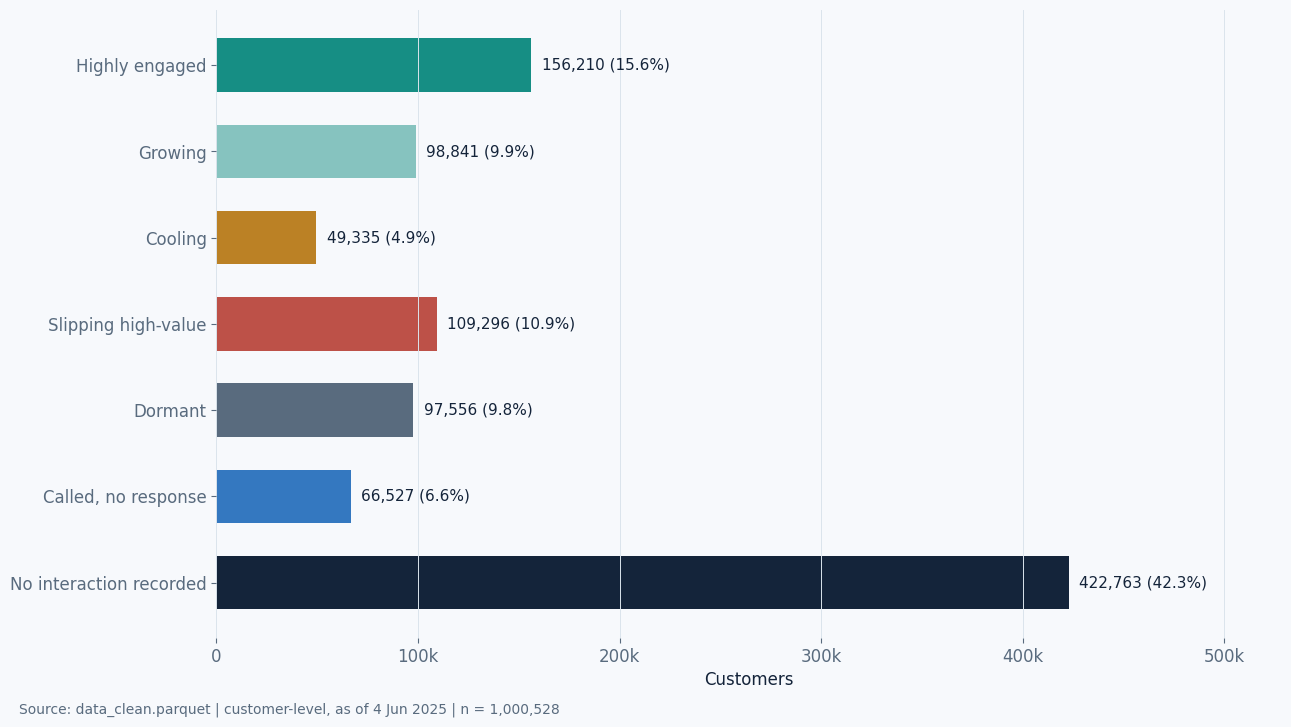

Insight: Highly engaged 15.6%; Growing 9.9%; Cooling 4.9%; Slipping high-value 10.9%; Dormant 9.8%; Called, no response 6.6%; No interaction recorded 42.3%.


In [13]:
tier_counts = d.engagement_tier.value_counts().reindex(TIERS, fill_value=0)
fig, ax = new_figure()
positions = np.arange(len(TIERS))
ax.barh(positions, tier_counts.values, color=TIER_COLORS, height=.62)
ax.set_yticks(positions, TIERS)
ax.invert_yaxis()
ax.grid(axis='x')
limit = tier_counts.max() * 1.25
ax.set_xlim(0, limit)
ax.set_xlabel('Customers')
count_axis(ax)
for i, value in enumerate(tier_counts.values):
    ax.text(value + limit * .01, i, f'{value:,} ({value / n:.1%})', va='center', fontsize=11)
finish(fig, '05_engagement_tiers.png')
say('tiers', '; '.join(f'{tier} {count / n:.1%}' for tier, count in tier_counts.items()) + '.')

**Figure 5 — Customers by engagement tier.** Tiers merge the RFM segments:
* Champions + Loyal → *Highly engaged*;
* Potential Loyalist + New + Promising → *Growing*;
* Need Attention + About to Sleep → *Cooling*;
* At Risk + Can't Lose → *Slipping high-value*;
* Hibernating + Lost → *Dormant*.

The two no-touchpoint groups are added. *Source:* `data_clean.parquet`, as of 4 Jun 2025.

## 8. Why same-window conversions cannot validate the score
A tempting test is whether engaged customers also applied for or signed a contract in the same
90-day window. In this data, that test is **circular**: lead records and scoring events are written
*by the application process itself*. The next chart shows how strongly they move together, so any
score built from them would "predict" applications by construction.

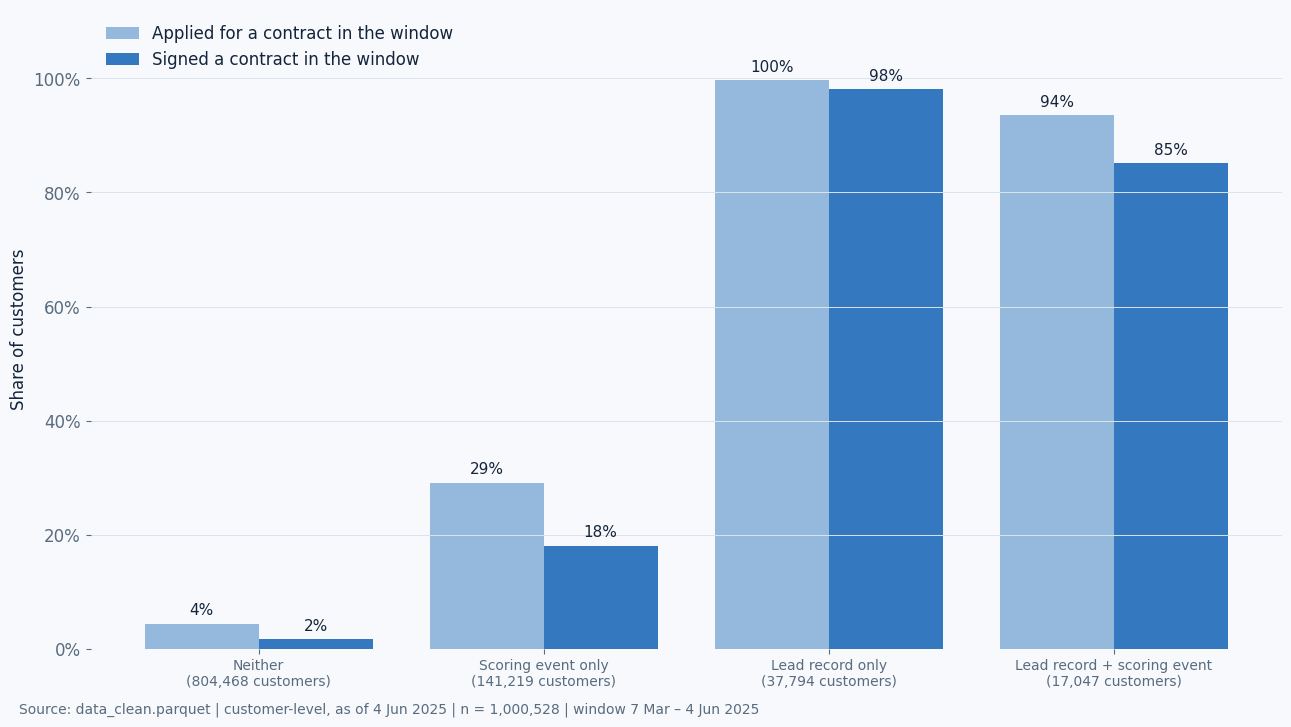

Insight: Customers with a lead record in the window applied at 100% versus 4% with neither; 92% of in-window leads were created within one day of the application. Lead records are application by-products, so same-window conversion is not used for validation.


In [14]:
lead90, behaviour90 = (d.leads_90d > 0).to_numpy(), (d.behavior_events_90d > 0).to_numpy()
applied90 = (d.last_application_at >= WINDOW_START).to_numpy()
signed90 = (d.last_signed_at >= WINDOW_START).to_numpy()
groups = pd.DataFrame({'lead record': lead90, 'scoring event': behaviour90, 'applied': applied90, 'signed': signed90})
groups['group'] = np.select([lead90 & behaviour90, lead90, behaviour90],
    ['Lead record + scoring event', 'Lead record only', 'Scoring event only'], default='Neither')
leakage = groups.groupby('group').agg(customers=('applied', 'size'), applied=('applied', 'mean'), signed=('signed', 'mean'))
leakage = leakage.reindex(['Neither', 'Scoring event only', 'Lead record only', 'Lead record + scoring event'])
leakage.to_csv(TABLES / 'c2_same_window_leakage.csv')
both = applied90 & d.last_lead_at.ge(WINDOW_START).to_numpy()
same_day = float((np.abs((d.last_lead_at - d.last_application_at).dt.days)[both] <= 1).mean())
fig, ax = new_figure(footer=FOOTER + ' | window 7 Mar – 4 Jun 2025')
positions = np.arange(len(leakage))
ax.bar(positions - .2, leakage.applied, width=.4, color=tint(BLUE), label='Applied for a contract in the window')
ax.bar(positions + .2, leakage.signed, width=.4, color=BLUE, label='Signed a contract in the window')
for i, row in enumerate(leakage.itertuples()):
    ax.text(i - .2, row.applied + .015, f'{row.applied:.0%}', ha='center', fontsize=11)
    ax.text(i + .2, row.signed + .015, f'{row.signed:.0%}', ha='center', fontsize=11)
ax.set_xticks(positions, [f'{g}\n({c:,} customers)' for g, c in zip(leakage.index, leakage.customers)], fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=None))
ax.set_ylim(0, 1.12)
ax.set_ylabel('Share of customers')
ax.grid(axis='y')
ax.legend(frameon=False, loc='upper left')
finish(fig, '06_same_window_leakage.png')
say('leakage', f"Customers with a lead record in the window applied at {leakage.loc['Lead record only', 'applied']:.0%} "
    f"versus {leakage.loc['Neither', 'applied']:.0%} with neither; {same_day:.0%} of in-window leads were created within "
    'one day of the application. Lead records are application by-products, so same-window conversion is not used for validation.')

**Figure 6 — Lead records and scoring events are by-products of applications.** Share of customers
who applied for or signed a contract in the 90-day window, grouped by whether they also have a lead
record or a scoring event in the same window.
*Source:* `data_clean.parquet`, 7 Mar – 4 Jun 2025.

## 9. Out-of-time validation
The only activity recorded after the cutoff is calls (5 Jun 2025 – 31 Aug 2026). The score is
frozen at 4 Jun 2025 and tested on two forward outcomes:

| Outcome | Population | Business meaning |
|---|---|---|
| Answered at least one call | customers called after the cutoff | reachability: a prerequisite for any telesales or service action |
| Made at least one inbound call | all customers | customer-initiated contact |

**Confounders.** Two exposures distort a naive comparison:
* The more often the company calls after the cutoff, the more chances a customer has to answer or
  call back.
* Customers never called before the cutoff could not show any call engagement, yet fresh numbers
  answer more often.

AUC is therefore **stratified**: customers are compared only with others in the same joint stratum
of post-cutoff call volume × pre-cutoff call volume (ten mid-rank bins each). The pooled AUC is
shown next to it.

* The 95% CIs come from a paired Poisson bootstrap (Hanley & MacGibbon, 2006, origin), so
  differences between scores also get CIs.
* Baselines: recency only, frequency only, interaction only, classic RFM with equal weights, the
  team's previous ad-hoc score, and company effort (calls placed in the 90 days before the cutoff).

In [15]:
calls_after = (d.calls_all - d.calls).to_numpy()
inbound_after = (d.inbound_all - d.inbound).to_numpy()
answered_after = (d.answered_all - d.answered).to_numpy()
outbound_after = calls_after - inbound_after

calls_before = d.calls.to_numpy()

def strata(*confounders):
    """Joint strata from ten mid-rank bins of each confounder (heavy ties share a bin)."""
    combined = np.zeros(len(confounders[0]), np.int64)
    for values in confounders:
        _, dense = np.unique(rank_bins(values, 10), return_inverse=True)
        combined = combined * 10 + dense
    return np.unique(combined, return_inverse=True)[1]

called_after = calls_after > 0
outcomes = {
    'Answered a call after cutoff': (called_after, answered_after > 0,
                                     strata(calls_after[called_after], calls_before[called_after])),
    'Inbound call after cutoff': (np.ones(n, bool), inbound_after > 0, strata(outbound_after, calls_before)),
}
for outcome, (mask, _, stratum) in outcomes.items():
    check(f'strata for {outcome.lower()}', int(stratum.max()) + 1)

def previous_team_score():
    """Re-implementation of the earlier ad-hoc score (45/30/10/10/5 weights, 90-day decay)."""
    activity = pd.concat([d.last_call_at, d.last_lead_at, d.last_behavior_at], axis=1).max(axis=1)
    days = (REFERENCE_DATE - activity.dt.normalize()).dt.days.clip(lower=0)
    recency = np.where(days.isna(), 0, 100 * np.exp(-days.fillna(0) / 90))
    def capped(column):
        values = d[column].clip(lower=0).to_numpy(float)
        positive = values[values > 0]
        cap = np.quantile(np.log1p(positive), .95) if len(positive) else 0
        return np.clip(np.log1p(values) / cap, 0, 1) * 100 if cap > 0 else np.zeros(n)
    frequency = .75 * capped('behavior_events_90d') + .25 * capped('calls_90d')
    return (.45 * recency + .30 * frequency + .10 * capped('inbound') + .10 * capped('leads_90d')
            + .05 * capped('behavior_products_90d'))

HEADLINE = 'Engagement Score'
SCORES = {
    HEADLINE: scheme_scores['D-CRITIC (primary)'],
    'Engagement, CRITIC weights': scheme_scores['CRITIC (Pearson)'],
    'Engagement, equal weights': scheme_scores['Equal weights'],
    'Recency only': -raw.R.fillna(raw.R.max() + 1).to_numpy(),
    'Frequency only': raw.F.to_numpy(),
    'Interaction only': raw.I.to_numpy(),
    'Classic RFM (equal)': weighted_score(WEIGHTS['Equal weights'], ['R', 'F', 'M']),
    'Previous team score': previous_team_score(),
    'Company effort (calls placed, 90d)': d.calls_90d.to_numpy(float),
}

def codes(values):
    _, inverse = np.unique(np.round(values, 6), return_inverse=True)
    return inverse, int(inverse.max()) + 1

def stratified_auc(code, k, y, w, stratum, n_strata):
    """Mann-Whitney AUC counting only pairs inside the same stratum; one stratum = ordinary AUC."""
    index = stratum * k + code
    pos = np.bincount(index, weights=w * y, minlength=n_strata * k).reshape(n_strata, k)
    neg = np.bincount(index, weights=w * (1 - y), minlength=n_strata * k).reshape(n_strata, k)
    below = np.cumsum(neg, axis=1) - neg
    return float((pos * (below + .5 * neg)).sum() / (pos.sum(1) * neg.sum(1)).sum())

prepared = {}
for outcome, (mask, y, stratum) in outcomes.items():
    for name, values in SCORES.items():
        code, k = codes(values[mask])
        prepared[(outcome, name)] = (code, k, y[mask].astype(float), stratum, int(stratum.max()) + 1)
ones = {outcome: np.ones(int(mask.sum())) for outcome, (mask, _, _) in outcomes.items()}
point = {key: (stratified_auc(c, k, y, ones[key[0]], s, m), stratified_auc(c, k, y, ones[key[0]], np.zeros_like(s), 1))
         for key, (c, k, y, s, m) in prepared.items()}
replicates = np.empty((BOOTSTRAP_REPLICATES, len(prepared)))
rng = np.random.default_rng(SEED)
for b in range(BOOTSTRAP_REPLICATES):
    weights = rng.poisson(1.0, n).astype(float)
    subset = {outcome: weights[mask] for outcome, (mask, _, _) in outcomes.items()}
    replicates[b] = [stratified_auc(c, k, y, subset[outcome], s, m) for (outcome, _), (c, k, y, s, m) in prepared.items()]
keys = list(prepared)
auc_rows = []
for i, (outcome, name) in enumerate(keys):
    diff = replicates[:, keys.index((outcome, HEADLINE))] - replicates[:, i]
    mask, y, _ = outcomes[outcome]
    auc_rows.append({'outcome': outcome, 'score': name,
        'stratified_auc': point[(outcome, name)][0], 'pooled_auc': point[(outcome, name)][1],
        'ci_low': np.percentile(replicates[:, i], 2.5), 'ci_high': np.percentile(replicates[:, i], 97.5),
        'headline_minus_this': point[(outcome, HEADLINE)][0] - point[(outcome, name)][0],
        'diff_ci_low': np.percentile(diff, 2.5), 'diff_ci_high': np.percentile(diff, 97.5),
        'population': int(mask.sum()), 'positives': int(y[mask].sum()), 'base_rate': float(y[mask].mean())})
auc_table = pd.DataFrame(auc_rows)
auc_table.to_csv(TABLES / 'c2_validation_auc.csv', index=False)
print(auc_table.pivot(index='score', columns='outcome', values='stratified_auc').reindex(list(SCORES)).round(3).to_string())

outcome                             Answered a call after cutoff  Inbound call after cutoff
score                                                                                      
Engagement Score                                           0.545                      0.633
Engagement, CRITIC weights                                 0.545                      0.633
Engagement, equal weights                                  0.550                      0.634
Recency only                                               0.536                      0.606
Frequency only                                             0.488                      0.561
Interaction only                                           0.599                      0.522
Classic RFM (equal)                                        0.520                      0.622
Previous team score                                        0.498                      0.611
Company effort (calls placed, 90d)                         0.521                

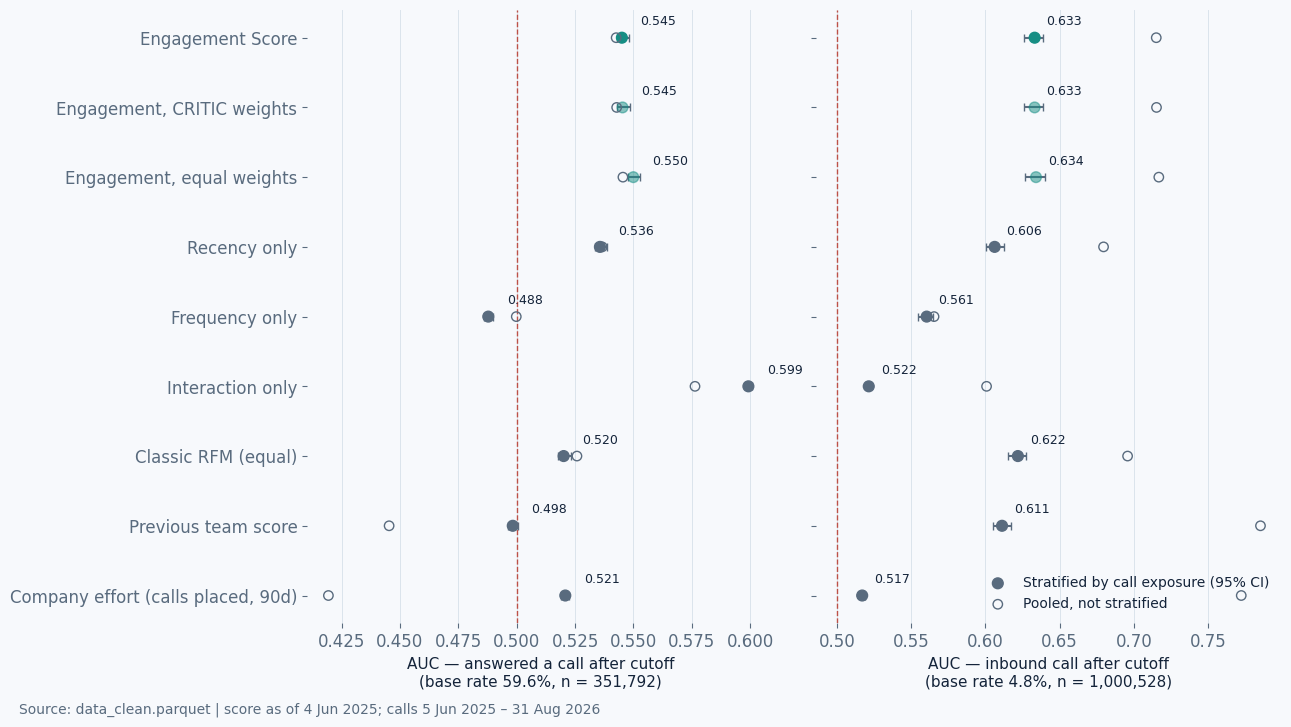

Insight: Answering a call after the cutoff: stratified AUC 0.545 (95% CI 0.543–0.548) versus 0.521 for company effort and 0.498 for the previous score. Inbound call: 0.633 (CI 0.626–0.639).


In [16]:
fig, axes = new_figure(1, 2, sharey=True, footer=FORWARD_FOOTER)
order = list(SCORES)[::-1]
y_pos = np.arange(len(order))
for ax, outcome in zip(axes, outcomes):
    part = auc_table[auc_table.outcome == outcome].set_index('score').reindex(order)
    colors = [TEAL if s == HEADLINE else tint(TEAL) if s.startswith('Engagement,') else SLATE for s in order]
    ax.errorbar(part.stratified_auc, y_pos, xerr=[part.stratified_auc - part.ci_low, part.ci_high - part.stratified_auc],
                fmt='none', ecolor=SLATE, capsize=3)
    ax.scatter(part.stratified_auc, y_pos, color=colors, s=60, zorder=3, label='Stratified by call exposure (95% CI)')
    ax.scatter(part.pooled_auc, y_pos, facecolors='none', edgecolors=SLATE, s=46, zorder=3, label='Pooled, not stratified')
    for yy, value in zip(y_pos, part.stratified_auc):
        ax.text(value + .008, yy + .18, f'{value:.3f}', fontsize=9)
    ax.axvline(.5, color=CORAL, linewidth=1, linestyle='--')
    ax.grid(axis='x')
    ax.set_xlabel(f'AUC — {outcome.lower()}\n(base rate {part.base_rate.iloc[0]:.1%}, n = {part.population.iloc[0]:,})', fontsize=11)
axes[0].set_yticks(y_pos, order)
axes[1].legend(frameon=False, loc='lower right', fontsize=10)
finish(fig, '07_validation_auc.png')
answer = auc_table[auc_table.outcome == 'Answered a call after cutoff'].set_index('score')
inbound_t = auc_table[auc_table.outcome == 'Inbound call after cutoff'].set_index('score')
say('validation', f"Answering a call after the cutoff: stratified AUC {answer.loc[HEADLINE, 'stratified_auc']:.3f} "
    f"(95% CI {answer.loc[HEADLINE, 'ci_low']:.3f}–{answer.loc[HEADLINE, 'ci_high']:.3f}) versus "
    f"{answer.loc['Company effort (calls placed, 90d)', 'stratified_auc']:.3f} for company effort and "
    f"{answer.loc['Previous team score', 'stratified_auc']:.3f} for the previous score. Inbound call: "
    f"{inbound_t.loc[HEADLINE, 'stratified_auc']:.3f} (CI {inbound_t.loc[HEADLINE, 'ci_low']:.3f}–"
    f"{inbound_t.loc[HEADLINE, 'ci_high']:.3f}).")

**Figure 7 — Out-of-time validation (AUC, 95% CI).** The solid markers are AUCs stratified by call
exposure (post-cutoff × pre-cutoff call volume); the hollow markers are pooled AUCs. 0.5 (dashed) is
random ranking. The
Engagement Score is dark teal, the same dimensions under other weights are light teal, and the
baselines are grey.
*Source:* `data_clean.parquet`; score as of 4 Jun 2025, calls 5 Jun 2025 – 31 Aug 2026.

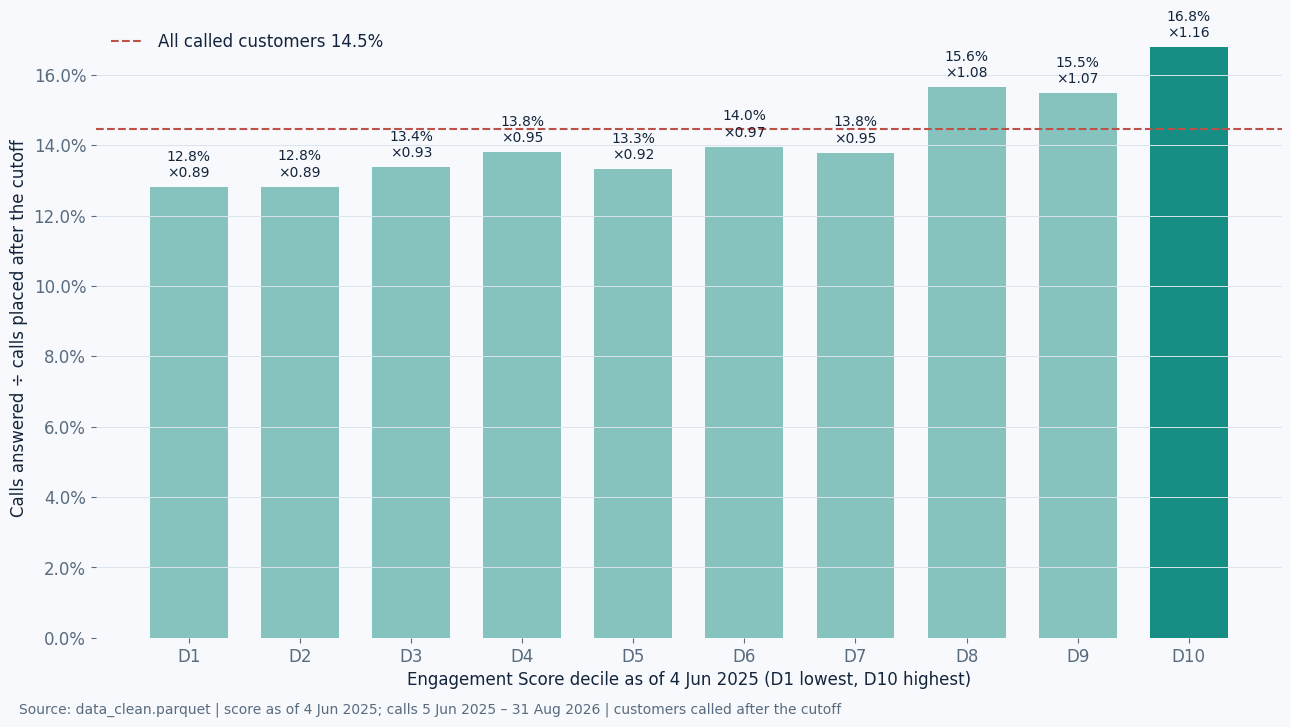

Insight: Answer rate after the cutoff: 16.8% in the top decile versus 12.8% in the bottom decile (pooled 14.5%); decile-rate Spearman ρ = 0.90.


In [17]:
def deciles(values, seed=SEED):
    tie_break = np.random.default_rng(seed).random(len(values))
    order_index = np.lexsort((tie_break, values))
    decile = np.empty(len(values), int)
    decile[order_index] = np.arange(len(values)) * 10 // len(values) + 1
    return decile

mask = called_after
forward_deciles = pd.DataFrame({'decile': deciles(d.engagement_score.to_numpy()[mask]),
    'answered': answered_after[mask], 'calls': calls_after[mask], 'any': answered_after[mask] > 0}).groupby('decile').agg(
    customers=('any', 'size'), any_answer=('any', 'mean'), answered=('answered', 'sum'), calls=('calls', 'sum'))
forward_deciles['answer_rate'] = forward_deciles.answered / forward_deciles.calls
pooled_rate = answered_after[mask].sum() / calls_after[mask].sum()
forward_deciles['lift'] = forward_deciles.answer_rate / pooled_rate
rho_decile = spearmanr(forward_deciles.index, forward_deciles.answer_rate).statistic
forward_deciles.to_csv(TABLES / 'c2_forward_answer_rate_by_decile.csv')
fig, ax = new_figure(footer=FORWARD_FOOTER + ' | customers called after the cutoff')
ax.bar(forward_deciles.index, forward_deciles.answer_rate, color=[tint(TEAL)] * 9 + [TEAL], width=.7)
ax.axhline(pooled_rate, color=CORAL, linestyle='--', linewidth=1.5, label=f'All called customers {pooled_rate:.1%}')
ax.set_xticks(range(1, 11), [f'D{v}' for v in range(1, 11)])
ax.set(xlabel='Engagement Score decile as of 4 Jun 2025 (D1 lowest, D10 highest)',
       ylabel='Calls answered ÷ calls placed after the cutoff')
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=None))
ax.grid(axis='y')
ax.legend(frameon=False, loc='upper left')
for decile, row in forward_deciles.iterrows():
    ax.text(decile, row.answer_rate + pooled_rate * .02, f'{row.answer_rate:.1%}\n×{row.lift:.2f}', ha='center', fontsize=10)
finish(fig, '08_forward_answer_rate_by_decile.png')
say('lift', f'Answer rate after the cutoff: {forward_deciles.answer_rate.iloc[-1]:.1%} in the top decile versus '
    f'{forward_deciles.answer_rate.iloc[0]:.1%} in the bottom decile (pooled {pooled_rate:.1%}); decile-rate Spearman '
    f'ρ = {rho_decile:.2f}.')

**Figure 8 — Answer rate after the cutoff by Engagement Score decile.** Calls answered divided by
calls placed between 5 Jun 2025 and 31 Aug 2026, for customers the company called in that period.
Deciles use the score frozen at 4 Jun 2025; ties are split at random with a fixed seed. The labels
show the rate and the lift over all called customers.
*Source:* `data_clean.parquet`.

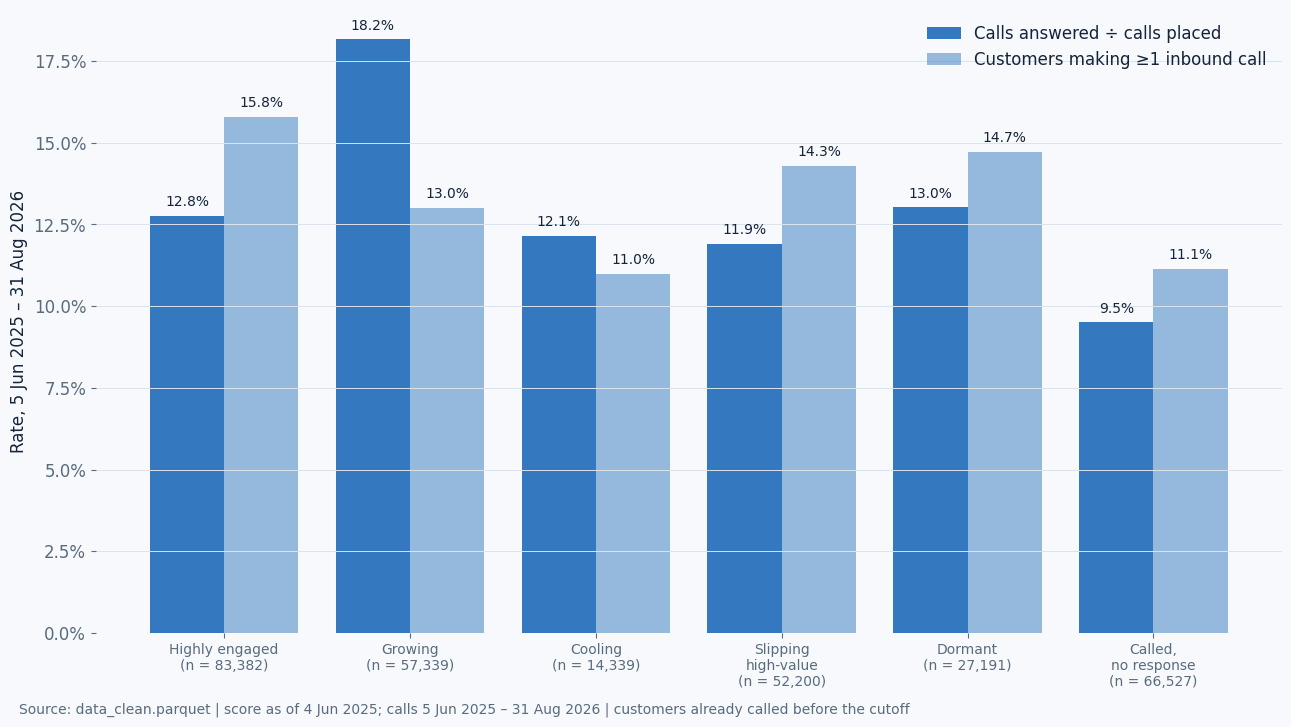

Insight: Among customers already called before the cutoff, Highly engaged customers answered 12.8% of later calls versus 9.5% for 'Called, no response'. Customers never called before answered 41.1% of their first calls versus 12.8% for previously called customers — a call-fatigue signal for Challenge 3.


In [18]:
forward = pd.DataFrame({'tier': d.engagement_tier, 'answered': answered_after, 'calls': calls_after,
                        'inbound': inbound_after > 0, 'called_before': calls_before > 0})

def forward_rates(frame):
    out = frame.groupby('tier').agg(customers=('tier', 'size'), inbound_rate=('inbound', 'mean'),
                                    answered_after=('answered', 'sum'), calls_after=('calls', 'sum'))
    out['answer_rate_after'] = out.answered_after / out.calls_after.where(out.calls_after > 0)
    return out.reindex(TIERS)

forward_profile = forward_rates(forward)
comparable = forward_rates(forward[forward.called_before]).dropna(subset=['customers'])
never_called = forward[~forward.called_before]
never_rate = never_called.answered.sum() / never_called.calls.sum()
called_rate = forward[forward.called_before].answered.sum() / forward[forward.called_before].calls.sum()
fig, ax = new_figure(footer=FORWARD_FOOTER + ' | customers already called before the cutoff')
positions = np.arange(len(comparable))
ax.bar(positions - .2, comparable.answer_rate_after, width=.4, color=BLUE, label='Calls answered ÷ calls placed')
ax.bar(positions + .2, comparable.inbound_rate, width=.4, color=tint(BLUE), label='Customers making ≥1 inbound call')
for i, (a, b) in enumerate(zip(comparable.answer_rate_after, comparable.inbound_rate)):
    ax.text(i - .2, a + .003, f'{a:.1%}', ha='center', fontsize=10)
    ax.text(i + .2, b + .003, f'{b:.1%}', ha='center', fontsize=10)
tick_names = [t.replace(', ', ',\n').replace(' high', '\nhigh') for t in comparable.index]
ax.set_xticks(positions, [f'{t}\n(n = {int(c):,})' for t, c in zip(tick_names, comparable.customers)], fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=None))
ax.set_ylabel('Rate, 5 Jun 2025 – 31 Aug 2026')
ax.grid(axis='y')
ax.legend(frameon=False, loc='upper right')
finish(fig, '09_forward_behaviour_by_tier.png')
cp = comparable
say('forward', f"Among customers already called before the cutoff, Highly engaged customers answered "
    f"{cp.loc['Highly engaged', 'answer_rate_after']:.1%} of later calls versus {cp.loc['Called, no response', 'answer_rate_after']:.1%} "
    f"for 'Called, no response'. Customers never called before answered {never_rate:.1%} of their first calls versus "
    f"{called_rate:.1%} for previously called customers — a call-fatigue signal for Challenge 3.")

**Figure 9 — Customer behaviour after the cutoff, by engagement tier.** Answer rate (calls
answered ÷ calls placed) and the share of customers who made at least one inbound call between
5 Jun 2025 and 31 Aug 2026. Only customers already called before the cutoff are shown, so that
every tier had the same opportunity to show call engagement. The *No interaction recorded* tier
was never called and is reported in the text. Who gets called is the company's choice, so this
shows association, not causation. *Source:* `data_clean.parquet`.

## 10. Drivers of engagement
Each candidate factor, measured before the cutoff, is assessed in three ways:
* **Rank correlation with the Engagement Score:** does it move with engagement?
* **Forward, exposure-adjusted AUC:** does it rank customers who later answered a call above those
  who did not, within the same call-exposure stratum? Above 0.5 means it raises future engagement;
  below 0.5 means it reduces it.
* **Information Value** for the same forward outcome, using Weight-of-Evidence bins as in credit
  scorecards (Siddiqi, 2017). Bands: <0.02 unpredictive, 0.02–0.1 weak, 0.1–0.3 medium, ≥0.3 strong.
  IV is not adjusted for call volume.

These are associations, **not causes**: targeting policy and seasonality confound them.

In [19]:
def information_value(x, y, max_bins=10):
    x = np.asarray(x, float)
    bins = np.full(len(x), -1)
    finite = np.isfinite(x)
    bins[finite & (x == 0)] = 0
    positive = finite & (x != 0)
    if positive.any():
        edges = np.unique(np.quantile(x[positive], np.linspace(0, 1, max_bins + 1)))
        bins[positive] = 1 + np.searchsorted(edges[1:-1], x[positive], side='right')
    table = pd.DataFrame({'bin': bins, 'y': y}).groupby('bin').y.agg(['sum', 'size'])
    events = table['sum'] + .5
    non_events = table['size'] - table['sum'] + .5
    pe, pn = events / events.sum(), non_events / non_events.sum()
    return float(((pe - pn) * np.log(pe / pn)).sum())

def iv_band(value):
    return 'unpredictive' if value < .02 else 'weak' if value < .1 else 'medium' if value < .3 else 'strong'

FACTORS = {
    'Days since last customer touchpoint': (raw.R, True),
    'Application / scoring events, 90d': (raw.F, True),
    'Signed credit amount (lifetime)': (raw.M, True),
    'Answered calls net of refusals': (raw.I, True),
    'Accepted lead offers': (raw.L, True),
    'Products applied for': (raw.P, True),
    'Inbound calls before cutoff': (d.inbound.astype(float), False),
    'Refused calls before cutoff': (d.refused.astype(float), False),
    'Not-interested lead outcomes': (d.lead_not_interested.astype(float), False),
    'Company calls placed, 90d': (d.calls_90d.astype(float), False),
    'Lead records, 90d': (d.leads_90d.astype(float), False),
    'App sessions per week (2025)': (d.app_sessions_week.astype(float), False),
    'Latest action self-service digital': (d.digital_last_action.astype(float), False),
    'Products explored in scoring, 90d': (d.behavior_products_90d.astype(float), False),
    'Rejected applications (lifetime)': (d.rejected_cases.astype(float), False),
}
mask, y_forward, stratum = outcomes['Answered a call after cutoff']
y_forward = y_forward[mask].astype(float)
engagement = d.engagement_score.to_numpy()
driver_rows = []
for factor, (values, is_input) in FACTORS.items():
    values = np.asarray(values, float)
    ok = np.isfinite(values)
    filled = np.where(ok, values, np.nanmax(values) + 1 if factor.startswith('Days') else 0)
    code, k = codes(filled[mask])
    auc = stratified_auc(code, k, y_forward, ones['Answered a call after cutoff'], stratum, int(stratum.max()) + 1)
    driver_rows.append({'factor': factor, 'score_input': is_input,
        'spearman_with_engagement': spearmanr(values[ok], engagement[ok]).statistic,
        'forward_auc_dial_adjusted': auc, 'iv_forward_answer': information_value(values[mask], y_forward)})
drivers = pd.DataFrame(driver_rows)
drivers['iv_band'] = drivers.iv_forward_answer.map(iv_band)
drivers['effect_on_future_engagement'] = np.where(drivers.forward_auc_dial_adjusted >= .5, 'raises', 'reduces')
drivers.to_csv(TABLES / 'c2_drivers.csv', index=False)
print(drivers.round(3).to_string(index=False))

                             factor  score_input  spearman_with_engagement  forward_auc_dial_adjusted  iv_forward_answer      iv_band effect_on_future_engagement
Days since last customer touchpoint         True                    -0.734                      0.464              0.029         weak                     reduces
  Application / scoring events, 90d         True                     0.579                      0.488              0.001 unpredictive                     reduces
    Signed credit amount (lifetime)         True                     0.820                      0.512              0.003 unpredictive                      raises
     Answered calls net of refusals         True                     0.330                      0.599              0.195       medium                      raises
               Accepted lead offers         True                     0.273                      0.500              0.000 unpredictive                      raises
               Products appl

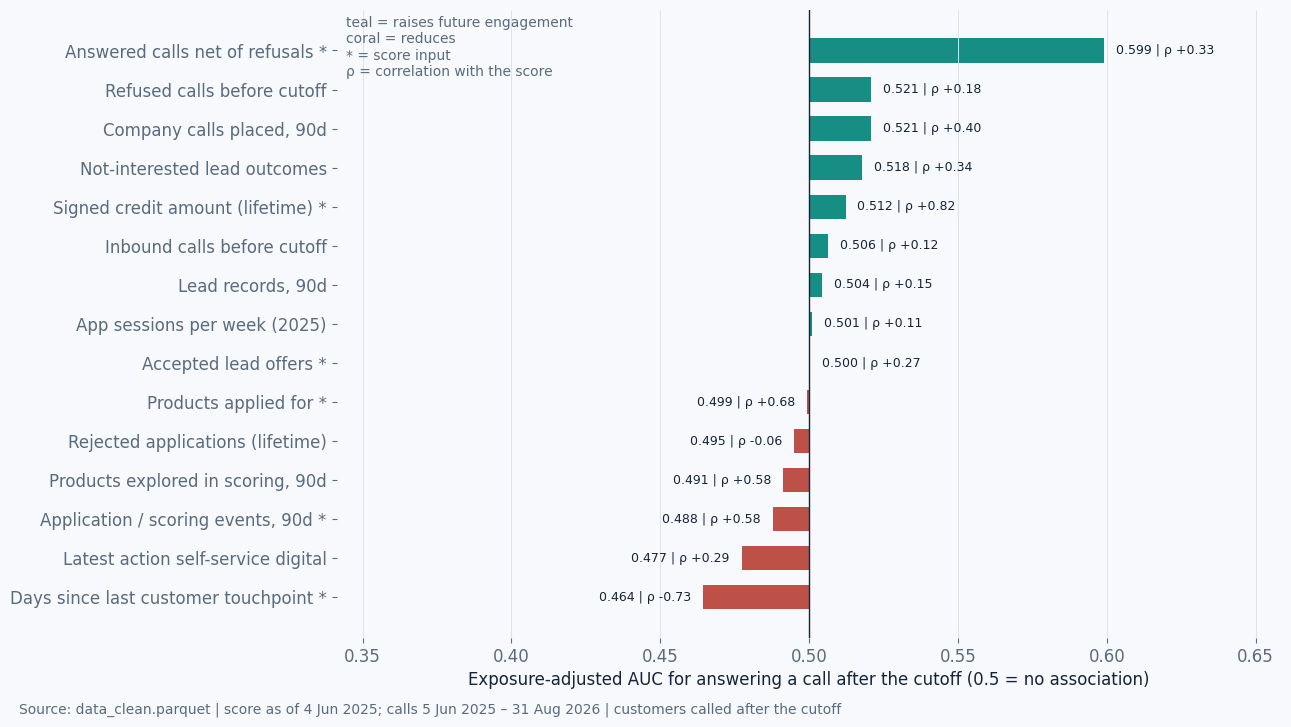

Insight: Raise future engagement most: Answered calls net of refusals (0.599); Refused calls before cutoff (0.521); Company calls placed, 90d (0.521). Reduce it most: Days since last customer touchpoint (0.464); Latest action self-service digital (0.477); Application / scoring events, 90d (0.488).


In [20]:
plot = drivers.assign(effect=drivers.forward_auc_dial_adjusted - .5).sort_values('effect')
fig, ax = new_figure(footer=FORWARD_FOOTER + ' | customers called after the cutoff')
positions = np.arange(len(plot))
ax.barh(positions, plot.effect, left=.5, color=[TEAL if e >= 0 else CORAL for e in plot.effect], height=.62)
ax.set_yticks(positions, [f"{f}{' *' if i else ''}" for f, i in zip(plot.factor, plot.score_input)])
ax.axvline(.5, color=NAVY, linewidth=1)
span = max(abs(plot.effect).max() * 1.6, .05)
ax.set_xlim(.5 - span, .5 + span)
for i, row in enumerate(plot.itertuples()):
    x_text = row.forward_auc_dial_adjusted + (.004 if row.effect >= 0 else -.004)
    ax.text(x_text, i, f'{row.forward_auc_dial_adjusted:.3f} | ρ {row.spearman_with_engagement:+.2f}',
            va='center', ha='left' if row.effect >= 0 else 'right', fontsize=9)
ax.set_xlabel('Exposure-adjusted AUC for answering a call after the cutoff (0.5 = no association)')
ax.grid(axis='x')
ax.text(.01, .99, 'teal = raises future engagement\ncoral = reduces\n* = score input\nρ = correlation with the score',
        transform=ax.transAxes, ha='left', va='top', color=SLATE, fontsize=10)
finish(fig, '10_engagement_drivers.png')
raises = drivers.sort_values('forward_auc_dial_adjusted', ascending=False).head(3)
reduces = drivers.sort_values('forward_auc_dial_adjusted').head(3)
say('drivers', 'Raise future engagement most: ' + '; '.join(f'{r.factor} ({r.forward_auc_dial_adjusted:.3f})' for r in raises.itertuples())
    + '. Reduce it most: ' + '; '.join(f'{r.factor} ({r.forward_auc_dial_adjusted:.3f})' for r in reduces.itertuples()) + '.')

**Figure 10 — Drivers of future engagement.** For each factor measured before the cutoff: its
exposure-adjusted AUC for answering a call afterwards (bars measured from 0.5) and its rank correlation
ρ with the Engagement Score. An asterisk marks a score input.
*Source:* `data_clean.parquet`; factors as of 4 Jun 2025, calls 5 Jun 2025 – 31 Aug 2026.

## 11. The engagement–stress paradox (hand-off to Challenge 3)
High engagement in consumer finance can mean **credit hunger** as well as healthy interest.
The `credit_seeking_flag` marks customers who meet all of these:
* their latest application falls in the 90-day window;
* that application was rejected;
* they have at least two rejected applications in total (repeated rejection).

Rejection is **not** part of the Engagement Score; it belongs to Financial Health. The chart is
descriptive and uses the same window.

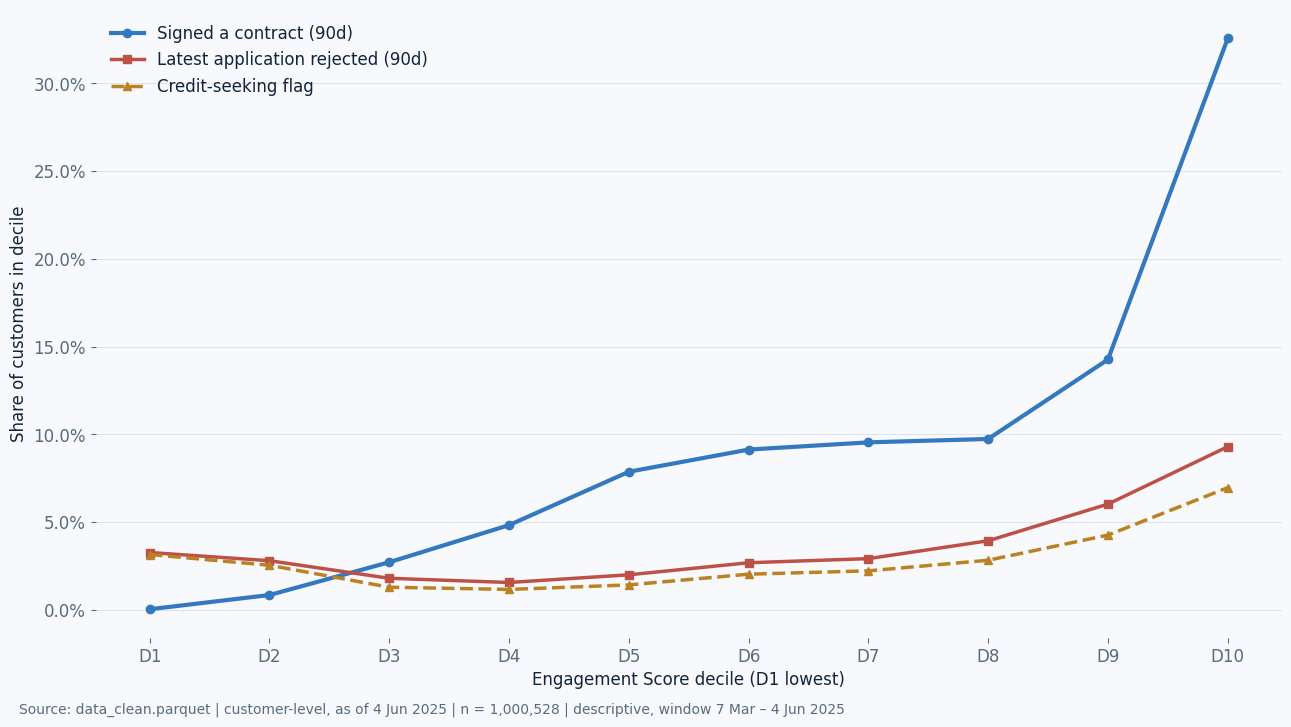

Insight: In the top engagement decile 33% signed, but 9% had their latest application rejected and 7.0% are flagged credit-seeking (bottom decile: 3% and 3.2%). Engagement alone must not trigger a credit offer.


In [21]:
recent_reject = (d.latest_status.eq('Rejected') & (d.last_application_at >= WINDOW_START)).to_numpy()
d['credit_seeking_flag'] = recent_reject & (d.rejected_cases >= 2).to_numpy()
paradox = pd.DataFrame({'decile': deciles(engagement), 'reject': recent_reject,
    'seeking': d.credit_seeking_flag, 'signed': signed90}).groupby('decile').mean()
paradox.to_csv(TABLES / 'c2_paradox_by_decile.csv')
fig, ax = new_figure(footer=FOOTER + ' | descriptive, window 7 Mar – 4 Jun 2025')
ax.plot(paradox.index, paradox.signed, color=BLUE, linewidth=3, marker='o', label='Signed a contract (90d)')
ax.plot(paradox.index, paradox.reject, color=CORAL, linewidth=2.5, marker='s', label='Latest application rejected (90d)')
ax.plot(paradox.index, paradox.seeking, color=AMBER, linewidth=2.5, marker='^', linestyle='--', label='Credit-seeking flag')
ax.set_xticks(range(1, 11), [f'D{v}' for v in range(1, 11)])
ax.set(xlabel='Engagement Score decile (D1 lowest)', ylabel='Share of customers in decile')
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=None))
ax.grid(axis='y')
ax.legend(frameon=False, loc='upper left')
finish(fig, '11_engagement_stress_paradox.png')
say('paradox', f'In the top engagement decile {paradox.signed.iloc[-1]:.0%} signed, but {paradox.reject.iloc[-1]:.0%} had their '
    f'latest application rejected and {paradox.seeking.iloc[-1]:.1%} are flagged credit-seeking (bottom decile: '
    f'{paradox.reject.iloc[0]:.0%} and {paradox.seeking.iloc[0]:.1%}). Engagement alone must not trigger a credit offer.')

**Figure 11 — Conversion and rejection rise together with engagement.** By Engagement Score decile:
the share who signed, the share whose latest application in the window was rejected, and the share
flagged credit-seeking. Descriptive only.
*Source:* `data_clean.parquet`, 7 Mar – 4 Jun 2025.

## 12. Sensitivity to the weighting scheme
Segments are weight-free by construction. The score is compared across D-CRITIC, Pearson CRITIC
and equal weights in two ways: the rank agreement between schemes, and the forward AUC of each
scheme (Figure 7).

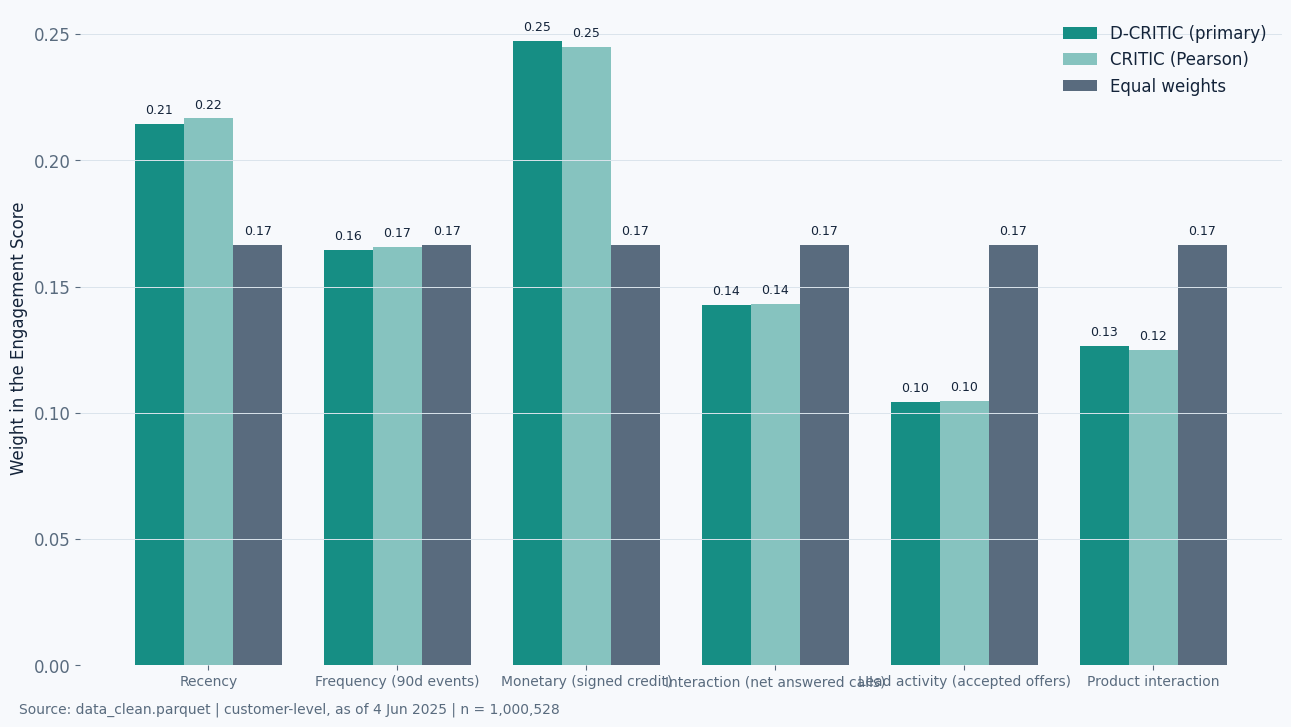

Insight: Rank agreement between weighting schemes: D-CRITIC (primary) vs CRITIC (Pearson) ρ = 1.000; D-CRITIC (primary) vs Equal weights ρ = 0.996; CRITIC (Pearson) vs Equal weights ρ = 0.996.


In [22]:
sensitivity = []
names_w = list(WEIGHTS)
for i, a in enumerate(names_w):
    for b in names_w[i + 1:]:
        sensitivity.append({'scheme_a': a, 'scheme_b': b,
            'spearman': spearmanr(scheme_scores[a], scheme_scores[b]).statistic,
            'mean_abs_diff': float(np.abs(scheme_scores[a] - scheme_scores[b]).mean())})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(TABLES / 'c2_weight_sensitivity.csv', index=False)
fig, ax = new_figure()
width = .26
positions = np.arange(len(DIMENSIONS))
for i, (name, color) in enumerate(zip(names_w, [TEAL, tint(TEAL), SLATE])):
    ax.bar(positions + (i - 1) * width, WEIGHTS[name], width=width, color=color, label=name)
    for x_pos, value in zip(positions + (i - 1) * width, WEIGHTS[name]):
        ax.text(x_pos, value + .004, f'{value:.2f}', ha='center', fontsize=9)
ax.set_xticks(positions, [labels[dim] for dim in DIMENSIONS], fontsize=10)
ax.set_ylabel('Weight in the Engagement Score')
ax.grid(axis='y')
ax.legend(frameon=False, loc='upper right')
finish(fig, '12_weight_sensitivity.png')
say('sensitivity', 'Rank agreement between weighting schemes: ' + '; '.join(
    f'{r.scheme_a} vs {r.scheme_b} ρ = {r.spearman:.3f}' for r in sensitivity.itertuples()) + '.')

**Figure 12 — Dimension weights under three schemes.** D-CRITIC is the primary scheme; Pearson
CRITIC and equal weights are the sensitivity checks. *Source:* `data_clean.parquet`, as of 4 Jun 2025.

## 13. Customer-level output and explanations
Each customer gets:
* the score and the six dimension scores;
* the RFM segment and the tier;
* the hand-off flags;
* a one-sentence explanation built from the same inputs as the score.

In [23]:
def fmt_int(series):
    return series.fillna(0).astype(int).astype(str)

touch_part = np.where(d.last_touch_at.notna(),
    'Last customer touchpoint ' + fmt_int(d.days_since_touch) + ' days ago via ' + d.touch_channel,
    'Customer-side activity on record but its date is not recoverable')
detail = ('; ' + fmt_int(raw.F) + ' application/scoring events in 90 days; ' + fmt_int(raw.I)
          + ' answered calls net of refusals; ' + fmt_int(raw.P) + ' product type(s) applied for')
detail = detail + np.where(raw.L > 0, '; accepted ' + fmt_int(raw.L) + ' lead offer(s)', '')
detail = detail + np.where(d.refused > 0, '; refused ' + fmt_int(d.refused) + ' call(s)', '')
detail = detail + np.where(d.credit_seeking_flag, '; repeated rejected applications (credit-seeking)', '')
called_only = 'Called ' + fmt_int(d.calls) + ' time(s) before the cutoff with no answered call, scoring event or lead response'
d['engagement_reason'] = np.where(d.engagement_tier.eq('Called, no response'), called_only,
    np.where(d.engagement_tier.eq('No interaction recorded'),
             'No calls, scoring events or lead responses recorded besides contract history', touch_part + detail)) + '.'

export = pd.DataFrame({'SKP_CLIENT': d.client, 'engagement_score': d.engagement_score,
    'engagement_tier': d.engagement_tier, 'rfm_segment': d.rfm_segment}
    | {f'{dim}_score': S[dim] for dim in DIMENSIONS}
    | {'FM_score': d.FM_score, 'days_since_customer_touch': d.days_since_touch,
       'last_touch_channel': d.touch_channel.mask(d.touch_channel.eq('')),
       'behavior_events_90d': raw.F.astype(int), 'signed_credit_total': raw.M,
       'net_answered_calls': raw.I.astype(int), 'accepted_lead_offers': raw.L.astype(int),
       'products_applied': raw.P.astype(int), 'refused_calls': d.refused, 'company_calls_90d': d.calls_90d,
       'credit_seeking_flag': d.credit_seeking_flag, 'engagement_reason': d.engagement_reason})
export.to_parquet(OUTPUTS / 'c2_engagement_scores.parquet', index=False, compression='zstd')
export.to_csv(OUTPUTS / 'c2_engagement_scores.csv', index=False, float_format='%.2f')
print(export.sample(5, random_state=1)[['SKP_CLIENT', 'engagement_score', 'engagement_tier', 'engagement_reason']].to_string(index=False))

 SKP_CLIENT  engagement_score         engagement_tier                                                                                                                                                                           engagement_reason
  117458754             17.05                 Cooling                                Last customer touchpoint 130 days ago via website; 0 application/scoring events in 90 days; 0 answered calls net of refusals; 1 product type(s) applied for.
  125460450             32.43                 Dormant Last customer touchpoint 168 days ago via partner site; 0 application/scoring events in 90 days; 0 answered calls net of refusals; 2 product type(s) applied for; accepted 1 lead offer(s).
   38130480             39.58     Slipping high-value                              Last customer touchpoint 154 days ago via telesales; 0 application/scoring events in 90 days; 0 answered calls net of refusals; 2 product type(s) applied for.
   16072800             24.87 No

In [24]:
profile = d.assign(signed=signed90, applied=applied90).groupby('engagement_tier').agg(
    customers=('client', 'size'), median_score=('engagement_score', 'median'),
    signed_90d=('signed', 'mean'), applied_90d=('applied', 'mean'),
    credit_seeking=('credit_seeking_flag', 'mean')).reindex(TIERS)
profile['share'] = profile.customers / n
profile = profile.join(forward_profile[['answer_rate_after', 'inbound_rate']]).join(
    comparable[['answer_rate_after']].rename(columns={'answer_rate_after': 'answer_rate_after_if_called_before'}))
profile = profile.join(S.assign(tier=d.engagement_tier.values).groupby('tier')[DIMENSIONS].mean().add_prefix('mean_'))
profile.to_csv(TABLES / 'c2_tier_profile.csv')
print(profile.round(3).to_string())

                         customers  median_score  signed_90d  applied_90d  credit_seeking  share  answer_rate_after  inbound_rate  answer_rate_after_if_called_before  mean_R  mean_F  mean_M  mean_I  mean_L  mean_P
engagement_tier                                                                                                                                                                                                      
Highly engaged              156210         58.53       0.246        0.323           0.056  0.156              0.139         0.096                               0.128   4.069   2.751   4.514   1.360   1.336   4.398
Growing                      98841         45.07       0.115        0.193           0.054  0.099              0.188         0.081                               0.182   4.406   1.862   2.901   1.677   1.134   3.726
Cooling                      49335         26.39       0.028        0.055           0.019  0.049              0.139         0.037               

## 14. Reports and final checks
The methodology and validation reports are generated from the computed tables, so every number in
them matches this run.

In [25]:
weights_md = '\n'.join(f"| {dim} | {labels[dim]} | {WEIGHTS['D-CRITIC (primary)'][i]:.3f} | "
    f"{WEIGHTS['CRITIC (Pearson)'][i]:.3f} | {WEIGHTS['Equal weights'][i]:.3f} |" for i, dim in enumerate(DIMENSIONS))
auc_md = '\n'.join(f"| {r.outcome} | {r.score} | {r.stratified_auc:.3f} | {r.ci_low:.3f}–{r.ci_high:.3f} | "
    f"{r.pooled_auc:.3f} | {r.headline_minus_this:+.3f} ({r.diff_ci_low:+.3f} to {r.diff_ci_high:+.3f}) |"
    for r in auc_table.itertuples())
tier_md = '\n'.join(f"| {t} | {int(r.customers):,} | {r.share:.1%} | {r.median_score:.1f} | "
    f"{'n/a (never called)' if pd.isna(r.answer_rate_after_if_called_before) else format(r.answer_rate_after_if_called_before, '.1%')} | "
    f"{r.inbound_rate:.1%} | {r.signed_90d:.1%} | {r.credit_seeking:.1%} |" for t, r in profile.iterrows())
driver_md = '\n'.join(f"| {r.factor} | {'yes' if r.score_input else ''} | {r.spearman_with_engagement:+.2f} | "
    f"{r.forward_auc_dial_adjusted:.3f} ({r.effect_on_future_engagement}) | {r.iv_forward_answer:.3f} ({r.iv_band}) |"
    for r in drivers.sort_values('forward_auc_dial_adjusted', ascending=False).itertuples())
quality_md = '\n'.join(f"| {c['check']} | {c['value']} | {'pass' if c['passed'] else 'FAIL'} |" for c in checks)
REFERENCES = '''1. Brito, J. B. G., Bucco, G. B., Heldt, R., Becker, J. L., Silveira, C. S., Luce, F. B., & Anzanello, M. J. (2024). A framework to improve churn prediction performance in retail banking. *Financial Innovation*, 10, 17. https://doi.org/10.1186/s40854-023-00558-3
2. European Commission, Joint Research Centre (2019). *Your 10-Step Pocket Guide to Composite Indicators & Scoreboards*. Knowledge4Policy, Competence Centre on Composite Indicators and Scoreboards.
3. Krishnan, A. R., Kasim, M. M., Hamid, R., & Ghazali, M. F. (2021). A modified CRITIC method to estimate the objective weights of decision criteria. *Symmetry*, 13(6), 973. https://doi.org/10.3390/sym13060973
4. Lim, W. M., Rasul, T., Kumar, S., & Ala, M. (2022). Past, present, and future of customer engagement. *Journal of Business Research*, 140, 439–458. https://doi.org/10.1016/j.jbusres.2021.11.014
5. Mena, C. G., Coussement, K., De Bock, K. W., De Caigny, A., & Lessmann, S. (2024). Exploiting time-varying RFM measures for customer churn prediction with deep neural networks. *Annals of Operations Research*, 339(1–2), 765–787.
6. Mosa, M., Agami, N., Elkhayat, G., & Kholief, M. (2023). A novel hybrid segmentation approach for decision support: A case study in banking. *The Computer Journal*, 66(5), 1228–. https://doi.org/10.1093/comjnl/bxac009 [VERIFY author order]
7. Pansari, A., & Kumar, V. (2017). Customer engagement: The construct, antecedents, and consequences. *Journal of the Academy of Marketing Science*, 45(3), 294–311.
8. Siddiqi, N. (2017). *Intelligent Credit Scoring: Building and Implementing Better Credit Risk Scorecards* (2nd ed.). Wiley.

Origins, cited for attribution only:
* Hughes (1994), *Strategic Database Marketing* — quintile RFM coding.
* Diakoulaki, Mavrotas & Papayannakis (1995), *Computers & Operations Research* 22(7) — CRITIC.
* Székely, Rizzo & Bakirov (2007), *Annals of Statistics* 35(6) — distance correlation.
* Hanley & MacGibbon (2006), *Computer Methods and Programs in Biomedicine* 83(1) — Poisson bootstrap.

The 11-segment R × FM grid is a widely used practitioner convention [VERIFY original source].'''

methodology = f'''# Challenge 2 — Customer Engagement Score: methodology

**Population:** {n:,} customers | **As of:** 4 Jun 2025 | **Input:** `data_clean.parquet` (SHA-256 `{source_hash[:16]}…`)

## Definition
Engagement is customer-initiated behaviour towards the company beyond a single transaction
(Pansari & Kumar, 2017; Lim et al., 2022). Only customer-side touchpoints count:
* applications and scoring through any channel;
* calls the customer answered, net of refusals;
* lead offers the customer accepted or initiated.

Calls placed by the company are company effort and are used only as a baseline.

## Dimensions (RFM+)
RFM is the backbone (Mena et al., 2024; Brito et al., 2024). The Interaction, Lead and Product
dimensions extend it, as RFMA does for banking (Mosa et al., 2023).

| Dim | Measure | Coding |
|---|---|---|
| R | days since the last customer-side touchpoint | quintiles among dated customers; most recent = 5; no date = 1 |
| F | application / scoring events, last 90 days | 0 → 1; positives in quartiles 2–5 |
| M | total signed credit amount | same as F |
| I | answered calls minus refusals | same as F |
| L | accepted lead offers | same as F |
| P | distinct products applied for | same as F |

Some customers' last answered call or recent accepted offer is not the latest record, so their date
gets a conservative bound: {int(answered_censored.sum()):,} customers (call) and {int(deal_censored.sum()):,} customers (offer).

## Weights (outcome-free)
D-CRITIC (Krishnan et al., 2021): `C_j = σ_j Σ_k (1 − dCor_jk)`, `w_j = C_j / ΣC`. Distance
correlation is computed exactly from the 5 × 5 joint frequency tables and checked against brute force.

The composite follows the JRC (2019) 10-step guide: framework → selection → treatment →
normalisation → weighting → aggregation → sensitivity → validation.

| Dim | Meaning | D-CRITIC | CRITIC | Equal |
|---|---|---|---|---|
{weights_md}

`Engagement = 100 × Σ w_j (s_j − 1) / 4`. Median: {median:.1f}.

## Segments and tiers
The R × FM grid (FM = mean of F and M, rounded half up) is applied in a fixed precedence order.
The segments are then merged into tiers, plus two groups without customer-side touchpoints.

| Tier | Customers | Share | Median score | Answer rate after cutoff (called before) | Inbound after cutoff | Signed (90d, descriptive) | Credit-seeking |
|---|---|---|---|---|---|---|---|
{tier_md}

## Why same-window conversions are not used for validation
{INSIGHTS['leakage']}

## Hand-off to Challenge 3
`credit_seeking_flag` = the latest application in the 90-day window was rejected **and** the customer
has at least two rejected applications in total. {INSIGHTS['paradox']}

## Limitations
* The customer file keeps only the latest call and lead, so some recency dates are bounds, not exact dates.
* Collection calls cannot be separated from sales calls in the customer-level file, so answered calls
  may include collection contacts.
* The only forward outcome is call behaviour. No contract data exists after 4 Jun 2025, so a forward
  conversion test is not possible with this file.
* Who gets called is the company's choice. Stratifying by call exposure controls for intensity, not for selection.
* `AVG_SESSION_PER_WEEK_2025` has no documented window, so it is analysed only as a candidate driver.
* Demographics are not used.

## References
{REFERENCES}
'''

validation_report = f'''# Challenge 2 — Validation report

The weights never see an outcome. The score is frozen at 4 Jun 2025, and the outcomes come only from
calls made between 5 Jun 2025 and 31 Aug 2026. AUCs are stratified jointly by post-cutoff and pre-cutoff call volume
(ten mid-rank bins each) to remove the "more calls, more chances" and "never called" effects. The 95% CIs come from
{BOOTSTRAP_REPLICATES} paired Poisson-bootstrap replicates (seed {SEED}).

## AUC by outcome
| Outcome | Score | Stratified AUC | 95% CI | Pooled AUC | Engagement minus this (95% CI) |
|---|---|---|---|---|---|
{auc_md}

## Key results
* {INSIGHTS['validation']}
* {INSIGHTS['lift']}
* {INSIGHTS['forward']}
* {INSIGHTS['sensitivity']}
* {INSIGHTS['leakage']}

## Drivers (association, not causation)
| Factor | Score input | ρ with score | Forward exposure-adjusted AUC | IV, forward answer (band) |
|---|---|---|---|---|
{driver_md}

## Data-quality checks
| Check | Value | Result |
|---|---|---|
{quality_md}

## Proposed causal test (for Challenge 3)
Randomly hold out a share of each tier from the Next Best Action campaign. Then compare answer,
application and signing rates between treated and holdout customers. This turns the associations
above into measured uplift.
'''
(REPORTS / 'C2_ENGAGEMENT_METHODOLOGY.md').write_text(methodology, encoding='utf-8')
(REPORTS / 'C2_VALIDATION_REPORT.md').write_text(validation_report, encoding='utf-8')
parameters = {'cutoff_exclusive': str(CUTOFF.date()), 'reference_date': str(REFERENCE_DATE.date()),
    'window_start': str(WINDOW_START.date()), 'call_data_start': str(CALL_DATA_START.date()),
    'self_lead_sources': sorted(SELF_LEAD_SOURCES),
    'coding': {'R': 'mid-rank quintiles among dated customers (Hughes 1994 origin)',
               'F/M/I/L/P': 'zero -> 1, positives mid-rank quartiles -> 2..5'},
    'weights': {name: dict(zip(DIMENSIONS, map(float, w))) for name, w in WEIGHTS.items()},
    'weights_reference': 'Krishnan et al. (2021) D-CRITIC; JRC (2019) 10-step guide',
    'segment_grid': [name for name, _ in SEGMENT_RULES], 'tiers': TIER_OF,
    'validation': {'design': 'out-of-time, forward call outcomes', 'strata': 'post-cutoff x pre-cutoff call volume, ten mid-rank bins each',
                   'bootstrap': {'replicates': BOOTSTRAP_REPLICATES, 'seed': SEED, 'type': 'paired Poisson'}},
    'iv_bands_reference': 'Siddiqi (2017)', 'source_sha256': source_hash}
(TABLES / 'c2_parameters.json').write_text(json.dumps(parameters, indent=2, default=str), encoding='utf-8')
pd.DataFrame(checks).to_csv(TABLES / 'c2_data_quality.csv', index=False)

with SOURCE.open('rb') as handle:
    unchanged = hashlib.file_digest(handle, 'sha256').hexdigest() == source_hash
final = pd.DataFrame([
    ('Brief 1-2: factors and R/F/Interaction/Lead/Product analysed', True),
    ('Brief 3: Engagement Score 0-100 for every customer', bool(export.engagement_score.between(0, 100).all())),
    ('Brief 4: segment and tier for every customer', bool(export.engagement_tier.notna().all())),
    ('Brief 5: drivers measured out of time', len(drivers) == len(FACTORS)),
    ('Brief 6: out-of-time validation with CIs', len(auc_table) == len(prepared)),
    ('Weights derived without outcomes', True),
    ('No demographic inputs', True),
    ('All figures saved without titles', len(FIGURE_LOG) == 12),
    ('Every customer has an explanation', bool(export.engagement_reason.str.len().gt(1).all())),
    ('Source parquet unchanged', unchanged),
], columns=['check', 'passed'])
print(final.to_string(index=False))
print(f'Exported {len(export):,} customers, {len(FIGURE_LOG)} figures, 2 reports.')

                                                       check  passed
Brief 1-2: factors and R/F/Interaction/Lead/Product analysed    True
          Brief 3: Engagement Score 0-100 for every customer    True
                Brief 4: segment and tier for every customer    True
                       Brief 5: drivers measured out of time    True
                    Brief 6: out-of-time validation with CIs    True
                            Weights derived without outcomes    True
                                       No demographic inputs    True
                            All figures saved without titles    True
                           Every customer has an explanation    True
                                    Source parquet unchanged    True
Exported 1,000,528 customers, 12 figures, 2 reports.
